In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from datetime import datetime

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

REPORTS_DIR = PROJECT_DIR / "outputs" / "reports"
CHARTS_DIR = PROJECT_DIR / "outputs" / "charts"
FORECASTS_DIR = PROJECT_DIR / "data" / "forecasts"
FINAL_DIR = PROJECT_DIR / "outputs" / "final_report"

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("PROJECT EXISTS:", PROJECT_DIR.exists())
print("REPORTS DIRECTORY:", REPORTS_DIR)
print("REPORTS DIRECTORY EXISTS:", REPORTS_DIR.exists())

if REPORTS_DIR.exists():
    print("\nAVAILABLE REPORT FILES:")
    for file in sorted(REPORTS_DIR.glob("*.csv")):
        print(file.name)
else:
    print("\nERROR: Reports directory not found.")

PROJECT DIRECTORY: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
PROJECT EXISTS: True
REPORTS DIRECTORY: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports
REPORTS DIRECTORY EXISTS: True

AVAILABLE REPORT FILES:
adf_stationarity_results.csv
all_instruments_stationarity.csv
annual_returns.csv
average_feature_importance.csv
backtest_benchmark_comparison.csv
backtest_daily_portfolio.csv
backtest_generated_signals.csv
backtest_instrument_performance.csv
backtest_monthly_returns.csv
backtest_performance_summary.csv
backtest_trade_log.csv
best_machine_learning_models.csv
best_statistical_models.csv
best_walk_forward_models.csv
bharatmarket_daily_signals.csv
bharatmarket_return_based_signals.csv
complete_eda_summary.csv
correlation_matrix.csv
daily_loss_limit_analysis.csv
data_processing_report.csv
data_quality_report.csv
data_validation_report.csv
descriptive_statistics.csv
feature_data_cleaning_report.csv
feature_engineering_summary.csv
final_best_model_by_i

In [4]:
def load_report(filename):
    path = REPORTS_DIR / filename

    if path.exists():
        try:
            df = pd.read_csv(path)
            print(f"Loaded: {filename} | Rows: {len(df)}")
            return df
        except Exception as e:
            print(f"Could not read {filename}: {e}")
            return pd.DataFrame()

    print(f"Missing: {filename}")
    return pd.DataFrame()


reports = {
    "data_quality": load_report("data_quality_report.csv"),
    "eda": load_report("complete_eda_summary.csv"),
    "statistical": load_report("statistical_forecasting_metrics.csv"),
    "best_statistical": load_report("best_statistical_models.csv"),
    "ml_comparison": load_report("return_based_model_comparison.csv"),
    "best_ml": load_report("return_based_best_models.csv"),
    "ml_walk_forward": load_report("return_based_walk_forward_results.csv"),
    "model_selection": load_report("statistical_vs_ml_model_selection.csv"),
    "backtest": load_report("backtest_performance_summary.csv"),
    "instrument_performance": load_report("backtest_instrument_performance.csv"),
    "monthly_returns": load_report("backtest_monthly_returns.csv"),
    "risk": load_report("risk_management_scorecard.csv"),
    "risk_contribution": load_report("instrument_risk_contribution.csv"),
    "forecast_signals": load_report("bharatmarket_return_based_signals.csv"),
    "forecast_errors": load_report("return_based_forecast_errors.csv"),
    "feature_importance": load_report("return_based_average_feature_importance.csv")
}

print("\nReport loading completed.")
print("Available report tables:", sum(not df.empty for df in reports.values()))

Loaded: data_quality_report.csv | Rows: 10
Loaded: complete_eda_summary.csv | Rows: 10
Loaded: statistical_forecasting_metrics.csv | Rows: 20
Loaded: best_statistical_models.csv | Rows: 10
Loaded: return_based_model_comparison.csv | Rows: 60
Loaded: return_based_best_models.csv | Rows: 10
Loaded: return_based_walk_forward_results.csv | Rows: 360
Loaded: statistical_vs_ml_model_selection.csv | Rows: 10
Loaded: backtest_performance_summary.csv | Rows: 1
Loaded: backtest_instrument_performance.csv | Rows: 3
Loaded: backtest_monthly_returns.csv | Rows: 11
Loaded: risk_management_scorecard.csv | Rows: 1
Loaded: instrument_risk_contribution.csv | Rows: 3
Loaded: bharatmarket_return_based_signals.csv | Rows: 10
Loaded: return_based_forecast_errors.csv | Rows: 0
Loaded: return_based_average_feature_importance.csv | Rows: 2480

Report loading completed.
Available report tables: 15


In [6]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

FINAL_DIR = PROJECT_DIR / "outputs" / "final_report"

# Create the directory and any missing parent directories
FINAL_DIR.mkdir(parents=True, exist_ok=True)

print("Final report directory:", FINAL_DIR)
print("Directory exists:", FINAL_DIR.exists())

Final report directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\final_report
Directory exists: True


In [7]:
project_summary = {
    "Project": "BharatMarket AI",
    "Project_Type": "Indian Stock Market Forecasting and Analytics",
    "Instruments": len(INSTRUMENTS),
    "Historical_Data_Source": "CSV",
    "Forecasting_Frequency": "Daily",
    "Statistical_Models": "Naive and Moving Average",
    "Machine_Learning_Models": (
        "Linear Regression, Decision Tree, Random Forest, "
        "Gradient Boosting, XGBoost"
    ),
    "Validation_Method": "Chronological Walk-Forward Validation",
    "Forecasting_Target": "Next-Day Return for ML; Price-Level Forecast for Statistical Models",
    "Backtesting": "Historical Paper-Trading Simulation",
    "Dashboard_Planned": "Streamlit",
    "Live_Data_Integration_Planned": "Upstox API"
}

summary_df = pd.DataFrame(
    list(project_summary.items()),
    columns=["Project_Component", "Details"]
)

display(summary_df)

summary_df.to_csv(
    FINAL_DIR / "final_project_summary.csv",
    index=False
)

with open(FINAL_DIR / "project_metadata.json", "w") as f:
    json.dump(project_summary, f, indent=4)

print("Project summary exported.")

,Project_Component,Details
0,Project,BharatMarket AI
1,Project_Type,Indian Stock Market Forecasting and Analytics
2,Instruments,10
3,Historical_Data_Source,CSV
4,Forecasting_Frequency,Daily
5,Statistical_Models,Naive and Moving Average
6,Machine_Learning_Models,"Linear Regression, Decision Tree, Random Fores..."
7,Validation_Method,Chronological Walk-Forward Validation
8,Forecasting_Target,Next-Day Return for ML; Price-Level Forecast f...
9,Backtesting,Historical Paper-Trading Simulation


Project summary exported.


In [8]:
model_selection = reports["model_selection"].copy()

if not model_selection.empty:
    display(model_selection)

    model_selection.to_csv(
        FINAL_DIR / "final_model_selection.csv",
        index=False
    )
else:
    print("Model selection report is unavailable.")

# Statistical performance
statistical = reports["statistical"].copy()

if not statistical.empty:
    print("\nSTATISTICAL MODEL PERFORMANCE")
    display(statistical.sort_values(["Instrument", "RMSE"]))

    statistical.to_csv(
        FINAL_DIR / "final_statistical_model_performance.csv",
        index=False
    )

# ML performance
ml_comparison = reports["ml_comparison"].copy()

if not ml_comparison.empty:
    print("\nMACHINE LEARNING MODEL PERFORMANCE")
    display(ml_comparison)

    ml_comparison.to_csv(
        FINAL_DIR / "final_ml_model_performance.csv",
        index=False
    )

,Instrument,Best_Statistical_Model,MAE,Statistical_RMSE,MAPE,Directional_Accuracy,Best_ML_Model,ML_Return_RMSE,Saved_Best_Model,Model_Agreement,Comparison_Note
0,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571,Zero Return Baseline,1.244205,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
1,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516,Gradient Boosting,1.590323,Gradient Boosting,True,Different targets and evaluation setups; RMSE ...
2,ICICIBANK,Moving Average 20,60.118663,80.998852,4.390726,53.225806,Zero Return Baseline,1.403294,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
3,INFY,Moving Average 20,265.625921,291.471253,23.609636,44.354839,Zero Return Baseline,2.094845,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
4,ITC,Naive,87.385448,94.016817,30.737768,45.967742,Linear Regression,1.381078,Linear Regression,True,Different targets and evaluation setups; RMSE ...
5,LT,Moving Average 20,145.251149,184.835515,3.737082,56.451613,Zero Return Baseline,1.728996,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
6,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806,Zero Return Baseline,0.973392,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
7,RELIANCE,Moving Average 20,147.544428,166.692434,11.342588,49.596774,Gradient Boosting,1.586508,Gradient Boosting,True,Different targets and evaluation setups; RMSE ...
8,SBIN,Naive,64.355911,86.337084,5.989208,50.403226,Gradient Boosting,1.648608,Zero Return Baseline,False,Different targets and evaluation setups; RMSE ...
9,TCS,Moving Average 20,511.189550,569.797784,22.221302,43.145161,Zero Return Baseline,2.024923,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...



STATISTICAL MODEL PERFORMANCE


,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
3,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571
2,BANKNIFTY,Naive,2583.721597,3219.899437,4.645027,50.202429
9,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516
8,HDFCBANK,Naive,183.864183,205.790608,24.259168,42.338710
13,ICICIBANK,Moving Average 20,60.118663,80.998852,4.390726,53.225806
12,ICICIBANK,Naive,59.738486,81.071113,4.427824,49.596774
11,INFY,Moving Average 20,265.625921,291.471253,23.609636,44.354839
10,INFY,Naive,282.838615,314.621684,25.292413,43.548387
16,ITC,Naive,87.385448,94.016817,30.737768,45.967742
17,ITC,Moving Average 20,92.711726,99.023896,32.542230,45.161290



MACHINE LEARNING MODEL PERFORMANCE


,Instrument,Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
0,BANKNIFTY,Decision Tree,1.045692,1.359331,592.800500,769.237779,0.165087,51.148459,100.0,244.586401
1,BANKNIFTY,Gradient Boosting,0.946209,1.239567,536.053950,701.538882,0.552529,51.162465,100.0,215.354065
2,BANKNIFTY,Linear Regression,1.079209,1.373935,612.547715,780.108066,0.474470,50.196078,100.0,133.004923
3,BANKNIFTY,Random Forest,0.936241,1.220353,529.952472,690.226942,0.621122,48.851541,100.0,226.933684
4,BANKNIFTY,XGBoost,0.916152,1.205055,519.327231,682.487285,0.651410,45.420168,100.0,225.198462
5,BANKNIFTY,Zero Return Baseline,0.904039,1.176572,511.130521,664.688814,0.675160,NaN,0.0,226.332996
6,HDFCBANK,Decision Tree,1.247569,1.584614,9.775271,12.445968,0.701095,49.103641,100.0,2.848926
7,HDFCBANK,Gradient Boosting,1.215628,1.545031,9.529327,12.156736,0.722470,42.927171,100.0,3.166703
8,HDFCBANK,Linear Regression,1.303406,1.640663,10.272154,13.013179,0.692833,44.747899,100.0,3.084896
9,HDFCBANK,Random Forest,1.239557,1.564365,9.701329,12.293204,0.713782,45.266106,100.0,3.133737


In [9]:
backtest = reports["backtest"].copy()
risk = reports["risk"].copy()

print("BACKTEST PERFORMANCE")
if not backtest.empty:
    display(backtest)
    backtest.to_csv(
        FINAL_DIR / "final_backtest_performance.csv",
        index=False
    )
else:
    print("Backtest summary not found.")

print("\nRISK MANAGEMENT PERFORMANCE")
if not risk.empty:
    display(risk)
    risk.to_csv(
        FINAL_DIR / "final_risk_management_performance.csv",
        index=False
    )
else:
    print("Risk report not found.")

print("\nINSTRUMENT PERFORMANCE")
if not reports["instrument_performance"].empty:
    display(reports["instrument_performance"])

print("\nMONTHLY RETURNS")
if not reports["monthly_returns"].empty:
    display(reports["monthly_returns"])

BACKTEST PERFORMANCE


,Initial_Capital,Final_Capital,Net_Profit,Total_Return_Pct,Total_Trades,Winning_Trades,Losing_Trades,Win_Rate_Pct,Gross_Profit,Gross_Loss,Profit_Factor,Average_Trade_PnL,Best_Trade,Worst_Trade,Maximum_Drawdown_Pct,Sharpe_Ratio
0,100000,103876.62367,3876.62367,3.876624,94,47,47,50.0,15233.900792,11357.277123,1.341334,41.240677,1403.780844,-1013.414302,-2.412466,1.143404



RISK MANAGEMENT PERFORMANCE


,Initial_Capital,Final_Capital,Net_Profit,Total_Return_Pct,Total_Trades,Win_Rate_Pct,Annualized_Return_Pct,Annualized_Volatility_Pct,Sharpe_Ratio,Sortino_Ratio,Maximum_Drawdown_Pct,Maximum_Consecutive_Losses,Daily_Loss_Breaches,Risk_Budget_Exceeded_Trades,Historical_VaR_95_Pct,Historical_CVaR_95_Pct
0,100000.0,103876.62367,3876.62367,3.876624,94,50.0,4.715743,4.103496,1.143404,1.962091,-2.412466,4,0,1,-0.295289,-0.54713



INSTRUMENT PERFORMANCE


,Instrument,Trades,Net_Profit,Average_Trade,Gross_Profit,Gross_Loss,Win_Rate_Pct,Profit_Factor
0,RELIANCE,42,3239.656145,77.134670,8431.516902,5191.860757,54.761905,1.623987
1,ITC,37,601.864666,16.266613,4866.426566,4264.561900,45.945946,1.141132
2,HDFCBANK,15,35.102859,2.340191,1935.957324,1900.854465,46.666667,1.018467



MONTHLY RETURNS


,Month,Starting_Equity,Ending_Equity,Net_PnL,Trades,Monthly_Return_Pct
0,2026-01,100000.000000,100163.066773,163.066773,2,0.163067
1,2026-02,100163.066773,99940.719980,-222.346794,7,-0.221985
2,2026-03,99940.719980,99533.834134,-406.885846,18,-0.407127
3,2026-04,99533.834134,101495.268870,1961.434736,8,1.970621
4,2026-05,101495.268870,101445.764901,-49.503969,8,-0.048775
5,2026-06,101445.764901,100847.505015,-598.259886,6,-0.589734
6,2026-07,100847.505015,100941.997899,94.492884,6,0.093699
7,2026-08,100941.997899,100444.243949,-497.753951,5,-0.493109
8,2026-09,100444.243949,100387.336436,-56.907513,12,-0.056656
9,2026-10,100387.336436,100546.932913,159.596478,12,0.158981


In [10]:
signals = reports["forecast_signals"].copy()

if not signals.empty:
    print("LATEST AVAILABLE FORECAST SIGNAL REPORT")
    display(signals)

    signals.to_csv(
        FINAL_DIR / "final_forecast_signals.csv",
        index=False
    )

    # Count signals if a suitable column exists
    signal_col = next(
        (c for c in signals.columns
         if c.lower() in ["signal", "trading_signal", "recommendation"]),
        None
    )

    if signal_col:
        print("\nSignal distribution:")
        display(signals[signal_col].value_counts().to_frame("Count"))
else:
    print("Forecast signal report not found.")

print("\nForecast errors:")
if not reports["forecast_errors"].empty:
    display(reports["forecast_errors"])

LATEST AVAILABLE FORECAST SIGNAL REPORT


,Instrument,Signal,RSI_14,MACD,MACD_Signal,Signal_Reason
0,NIFTY50,HOLD,66.986059,649.303766,565.925659,Forecast movement is below the signal threshol...
1,BANKNIFTY,HOLD,67.708396,2063.962792,1561.537568,Forecast movement is below the signal threshol...
2,RELIANCE,HOLD,64.888829,39.365804,34.045126,Forecast movement is below the signal threshol...
3,TCS,HOLD,57.150142,15.539041,32.225377,Forecast movement is below the signal threshol...
4,HDFCBANK,HOLD,65.190952,30.638457,24.811531,MACD bearish confirmation is absent.
5,INFY,HOLD,45.386176,0.668282,10.773014,Forecast movement is below the signal threshol...
6,ICICIBANK,HOLD,65.342783,60.902883,54.626167,Forecast movement is below the signal threshol...
7,SBIN,HOLD,70.279529,45.292410,31.980583,Forecast movement is below the signal threshol...
8,ITC,HOLD,73.015191,9.189864,7.005816,Forecast movement is below the signal threshol...
9,LT,HOLD,59.081114,102.224788,96.340299,Forecast movement is below the signal threshol...



Signal distribution:


,Count
Signal,
HOLD,10



Forecast errors:


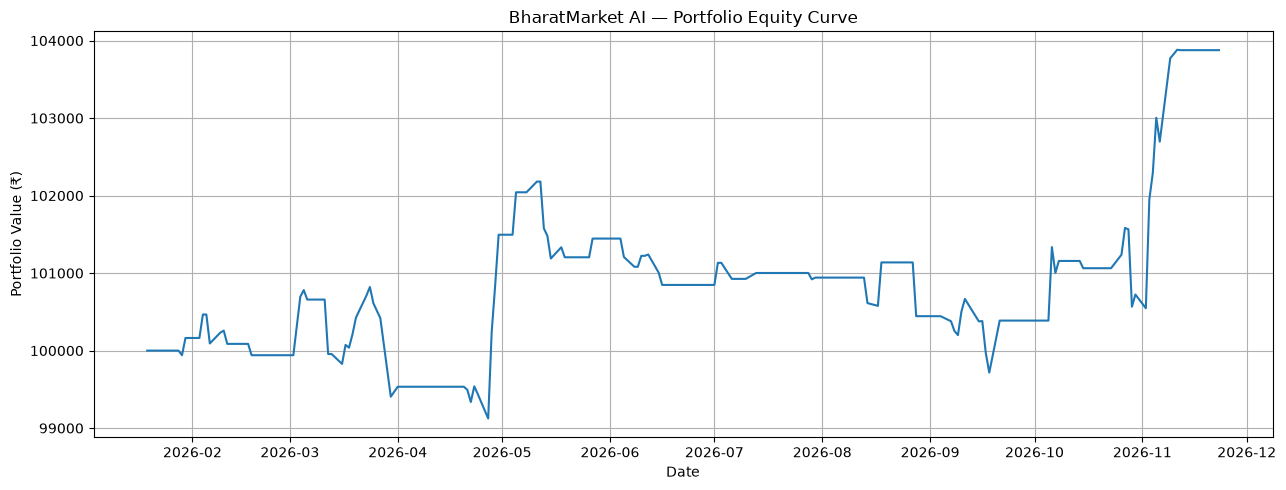

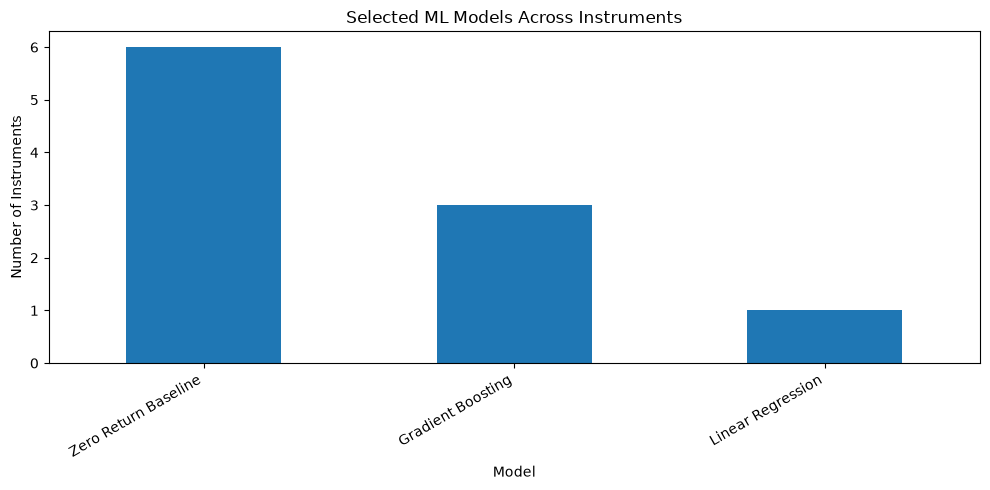

Final chart generation completed.


In [11]:
# Backtest equity curve
daily_path = REPORTS_DIR / "backtest_daily_portfolio.csv"

if daily_path.exists():
    daily = pd.read_csv(daily_path)

    date_col = next(
        (c for c in daily.columns if "date" in c.lower()),
        None
    )

    equity_col = next(
        (c for c in daily.columns
         if "equity" in c.lower() or "portfolio_value" in c.lower()),
        None
    )

    if date_col and equity_col:
        daily[date_col] = pd.to_datetime(daily[date_col])

        plt.figure(figsize=(13, 5))
        plt.plot(daily[date_col], daily[equity_col])
        plt.title("BharatMarket AI — Portfolio Equity Curve")
        plt.xlabel("Date")
        plt.ylabel("Portfolio Value (₹)")
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            CHARTS_DIR / "final_portfolio_equity_curve.png",
            dpi=300
        )
        plt.show()

# Model selection chart
if not model_selection.empty and "Best_ML_Model" in model_selection.columns:
    counts = model_selection["Best_ML_Model"].value_counts()

    plt.figure(figsize=(10, 5))
    counts.plot(kind="bar")
    plt.title("Selected ML Models Across Instruments")
    plt.xlabel("Model")
    plt.ylabel("Number of Instruments")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    plt.savefig(
        CHARTS_DIR / "final_ml_model_selection.png",
        dpi=300
    )
    plt.show()

print("Final chart generation completed.")

In [12]:
report_lines = []

report_lines.append("# BHARATMARKET AI")
report_lines.append("## Final Integrated Project Report")
report_lines.append("")
report_lines.append(f"Report generated: {datetime.now().strftime('%d %B %Y, %H:%M')}")
report_lines.append("")
report_lines.append("## 1. Project Overview")
report_lines.append(
    "BharatMarket AI is an Indian stock market forecasting and analytics "
    "project covering ten market instruments. It combines historical data "
    "validation, exploratory analysis, technical feature engineering, "
    "statistical forecasting, machine learning, walk-forward validation, "
    "signal generation, backtesting and portfolio risk analysis."
)
report_lines.append("")
report_lines.append("## 2. Instruments")
report_lines.extend([f"- {x}" for x in INSTRUMENTS])
report_lines.append("")
report_lines.append("## 3. Methodology")
report_lines.extend([
    "- Historical market data is stored in CSV files.",
    "- Data is validated and cleaned before feature engineering.",
    "- Statistical models and machine-learning models are evaluated.",
    "- Chronological validation is used to respect time ordering.",
    "- The ML forecasting target is next-day return.",
    "- Statistical forecasts use a price-level target.",
    "- Trading strategies are evaluated through historical simulation."
])
report_lines.append("")
report_lines.append("## 4. Model Evaluation")
report_lines.append(
    "Statistical and machine-learning evaluation results are reported "
    "separately because their forecasting targets and error units differ."
)
report_lines.append("")
report_lines.append("## 5. Backtesting and Risk")
report_lines.append(
    "The backtesting and risk-management reports contain the simulated "
    "portfolio results, trading performance, drawdown and risk metrics. "
    "These are historical simulation outputs, not guarantees of future returns."
)
report_lines.append("")
report_lines.append("## 6. Limitations")
report_lines.extend([
    "- Historical data and model performance may not represent future market conditions.",
    "- Daily forecasts are not equivalent to intraday predictions.",
    "- Underlying price forecasts do not establish options premium or options P&L performance.",
    "- The backtest uses assumptions about execution, costs and daily OHLC prices.",
    "- Statistical price-level RMSE and ML return RMSE are not directly comparable.",
    "- Live market integration and automated data updates are planned future work."
])
report_lines.append("")
report_lines.append("## 7. Future Enhancements")
report_lines.extend([
    "- Upstox API integration for live market data.",
    "- Automated daily historical data updates.",
    "- Streamlit-based interactive dashboard.",
    "- Model monitoring and periodic retraining.",
    "- Separate intraday forecasting models.",
    "- Expanded transaction-cost and execution modelling."
])

final_report_text = "\n".join(report_lines)

report_path = FINAL_DIR / "BharatMarket_AI_Final_Report.md"
report_path.write_text(final_report_text, encoding="utf-8")

print(final_report_text)
print("\nFinal written report saved:", report_path)

# BHARATMARKET AI
## Final Integrated Project Report

Report generated: 25 November 2026, 17:44

## 1. Project Overview
BharatMarket AI is an Indian stock market forecasting and analytics project covering ten market instruments. It combines historical data validation, exploratory analysis, technical feature engineering, statistical forecasting, machine learning, walk-forward validation, signal generation, backtesting and portfolio risk analysis.

## 2. Instruments
- NIFTY50
- BANKNIFTY
- RELIANCE
- TCS
- HDFCBANK
- INFY
- ICICIBANK
- SBIN
- ITC
- LT

## 3. Methodology
- Historical market data is stored in CSV files.
- Data is validated and cleaned before feature engineering.
- Statistical models and machine-learning models are evaluated.
- Chronological validation is used to respect time ordering.
- The ML forecasting target is next-day return.
- Statistical forecasts use a price-level target.
- Trading strategies are evaluated through historical simulation.

## 4. Model Evaluation
Sta

In [13]:
print("=" * 65)
print("BHARATMARKET AI — FINAL REPORT VERIFICATION")
print("=" * 65)

for folder in [REPORTS_DIR, CHARTS_DIR, FORECASTS_DIR, FINAL_DIR]:
    print(f"\n{folder.name}: {folder.exists()}")

print("\nFINAL REPORT FILES")
for file in sorted(FINAL_DIR.glob("*")):
    print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

print("\nFINAL PROJECT STATUS")
print("Project:", "BharatMarket AI")
print("Instruments:", len(INSTRUMENTS))
print("Notebooks completed:", "01–12")
print("Final integrated report:", report_path.exists())

print("\nNotebook 13 execution completed.")

BHARATMARKET AI — FINAL REPORT VERIFICATION

reports: True

charts: True

forecasts: True

final_report: True

FINAL REPORT FILES
BharatMarket_AI_Final_Report.md | 2.15 KB
final_backtest_performance.csv | 0.45 KB
final_forecast_signals.csv | 1.55 KB
final_ml_model_performance.csv | 9.29 KB
final_model_selection.csv | 2.53 KB
final_project_summary.csv | 0.58 KB
final_risk_management_performance.csv | 0.5 KB
final_statistical_model_performance.csv | 1.88 KB
project_metadata.json | 0.67 KB

FINAL PROJECT STATUS
Project: BharatMarket AI
Instruments: 10
Notebooks completed: 01–12
Final integrated report: True

Notebook 13 execution completed.


In [14]:
%pip install requests pandas numpy python-dotenv websocket-client

  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
Using cached python_dotenv-1.2.4-py3-none-any.whl (23 kB)
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [15]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_DIR}"
    )

UPSTOX_DIR = PROJECT_DIR / "upstox_integration"

folders = [
    UPSTOX_DIR,
    UPSTOX_DIR / "config",
    UPSTOX_DIR / "data",
    UPSTOX_DIR / "logs",
    UPSTOX_DIR / "src",
    UPSTOX_DIR / "tests",
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

print("UPSTOX INTEGRATION STRUCTURE")
print("=" * 50)

for folder in folders:
    print("CREATED:", folder)

print("\nProject directory verified:", PROJECT_DIR)

UPSTOX INTEGRATION STRUCTURE
CREATED: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration
CREATED: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\config
CREATED: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\data
CREATED: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\logs
CREATED: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\src
CREATED: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\tests

Project directory verified: C:\Users\adity\Downloads\Historical data\BharatMarket_AI


In [16]:
env_path = PROJECT_DIR / ".env"

if not env_path.exists():
    env_path.write_text(
        "UPSTOX_ACCESS_TOKEN=\n",
        encoding="utf-8"
    )
    print(".env file created.")
else:
    print(".env already exists. Existing credentials preserved.")

print("Location:", env_path)


.env file created.
Location: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\.env


In [17]:
gitignore_path = PROJECT_DIR / ".gitignore"

protected_entries = [
    ".env",
    ".env.*",
    "!.env.example",
    "__pycache__/",
    "*.pyc",
    "upstox_integration/logs/",
]

existing = (
    gitignore_path.read_text(encoding="utf-8")
    if gitignore_path.exists()
    else ""
)

with gitignore_path.open("a", encoding="utf-8") as f:
    for entry in protected_entries:
        if entry not in existing.splitlines():
            f.write(entry + "\n")

print(".gitignore updated.")
print("Credentials and local logs are protected from Git.")

.gitignore updated.
Credentials and local logs are protected from Git.


In [18]:
config_file = UPSTOX_DIR / "config" / "settings.py"

config_code = '''
from pathlib import Path
import os
from dotenv import load_dotenv

PROJECT_DIR = Path(
    r"C:\\Users\\adity\\Downloads\\Historical data\\BharatMarket_AI"
)

load_dotenv(PROJECT_DIR / ".env")

UPSTOX_ACCESS_TOKEN = os.getenv("UPSTOX_ACCESS_TOKEN", "").strip()

BASE_URL = "https://api.upstox.com"

INSTRUMENTS = [
    "NIFTY50",
    "BANKNIFTY",
    "RELIANCE",
    "TCS",
    "HDFCBANK",
    "INFY",
    "ICICIBANK",
    "SBIN",
    "ITC",
    "LT",
]
'''

config_file.write_text(config_code.strip() + "\n", encoding="utf-8")

print("Configuration file created:", config_file)

Configuration file created: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\config\settings.py


In [19]:
import sys
import importlib.util
from pathlib import Path
from dotenv import load_dotenv
import os

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

UPSTOX_DIR = PROJECT_DIR / "upstox_integration"

load_dotenv(PROJECT_DIR / ".env", override=True)

packages = [
    "requests",
    "pandas",
    "numpy",
    "dotenv",
    "websocket",
]

print("PACKAGE CHECK")
print("=" * 45)

all_packages_ok = True

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{'PASS' if installed else 'FAIL'}: {package}")
    all_packages_ok = all_packages_ok and installed

print("\nFOLDER CHECK")
for folder in [
    "config", "data", "logs", "src", "tests"
]:
    path = UPSTOX_DIR / folder
    print(f"{'PASS' if path.exists() else 'FAIL'}: {folder}")

token = os.getenv("UPSTOX_ACCESS_TOKEN", "").strip()

print("\nCREDENTIAL CHECK")
print("Token configured:", bool(token))
print("Token value: [HIDDEN]")

print("\nPROJECT CHECK")
print("Project exists:", PROJECT_DIR.exists())
print("Python version:", sys.version.split()[0])

if all_packages_ok and token:
    print("\nSTEP 1 STATUS: READY")
elif not all_packages_ok:
    print("\nSTEP 1 STATUS: PACKAGES NEED ATTENTION")
else:
    print("\nSTEP 1 STATUS: ADD YOUR TOKEN TO .env")

PACKAGE CHECK
PASS: requests
PASS: pandas
PASS: numpy
PASS: dotenv
PASS: websocket

FOLDER CHECK
PASS: config
PASS: data
PASS: logs
PASS: src
PASS: tests

CREDENTIAL CHECK
Token configured: True
Token value: [HIDDEN]

PROJECT CHECK
Project exists: True
Python version: 3.15.2

STEP 1 STATUS: READY


Cell 2

In [20]:
import requests
import gzip
import json
from pathlib import Path
from datetime import datetime

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

UPSTOX_DIR = PROJECT_DIR / "upstox_integration"
DATA_DIR = UPSTOX_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

INSTRUMENT_MASTER_URL = (
    "https://assets.upstox.com/market-quote/"
    "instruments/exchange/NSE.json.gz"
)

gz_path = DATA_DIR / "NSE_instruments.json.gz"
json_path = DATA_DIR / "NSE_instruments.json"

response = requests.get(
    INSTRUMENT_MASTER_URL,
    timeout=60
)

response.raise_for_status()

gz_path.write_bytes(response.content)

print("Downloaded instrument master.")
print("File size:", round(len(response.content) / (1024 * 1024), 2), "MB")

with gzip.open(gz_path, "rt", encoding="utf-8") as f:
    instruments_data = json.load(f)

if not isinstance(instruments_data, list):
    raise ValueError(
        "Unexpected instrument master format. Expected a JSON list."
    )

json_path.write_text(
    json.dumps(instruments_data, indent=2),
    encoding="utf-8"
)

print("Total instrument records:", len(instruments_data))
print("JSON file saved:", json_path)
print("\nSample record:")
print(json.dumps(instruments_data[0], indent=2))

Downloaded instrument master.
File size: 2.07 MB
Total instrument records: 87128
JSON file saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\data\NSE_instruments.json

Sample record:
{
  "segment": "NSE_EQ",
  "name": "SDL RJ 7.49% 2035",
  "exchange": "NSE",
  "isin": "IN2920250163",
  "instrument_type": "SG",
  "instrument_key": "NSE_EQ|IN2920250163",
  "lot_size": 100,
  "freeze_quantity": 100000.0,
  "exchange_token": "758718",
  "tick_size": 1.0,
  "trading_symbol": "749RJ35",
  "qty_multiplier": 1.0,
  "security_type": "NORMAL"
}


In [21]:
import pandas as pd

instrument_df = pd.DataFrame(instruments_data)

required_columns = [
    "segment",
    "name",
    "instrument_type",
    "instrument_key",
    "trading_symbol"
]

missing_columns = [
    col for col in required_columns
    if col not in instrument_df.columns
]

if missing_columns:
    raise ValueError(
        f"Instrument master is missing columns: {missing_columns}"
    )

print("Available segments:")
display(instrument_df["segment"].value_counts().to_frame("Count"))

print("\nNSE indices:")
nse_indices = instrument_df[
    (instrument_df["segment"] == "NSE_INDEX") &
    (instrument_df["instrument_type"] == "INDEX")
]

display(
    nse_indices[
        ["name", "trading_symbol", "instrument_key"]
    ].head(30)
)

print("\nSelected equity records:")
selected_equities = instrument_df[
    (instrument_df["segment"] == "NSE_EQ") &
    (instrument_df["instrument_type"] == "EQ") &
    (instrument_df["trading_symbol"].isin([
        "RELIANCE", "TCS", "HDFCBANK", "INFY",
        "ICICIBANK", "SBIN", "ITC", "LT"
    ]))
]

display(
    selected_equities[
        ["name", "trading_symbol", "instrument_key"]
    ]
)

Available segments:


,Count
segment,
NSE_FO,37910
NSE_COM,29275
NSE_EQ,9906
NCD_FO,9898
NSE_INDEX,139



NSE indices:


,name,trading_symbol,instrument_key
1434,NIFTY100 Qualty30,NIFTY100 QUALTY30,NSE_INDEX|NIFTY100 Qualty30
2546,Nifty Consumption,NIFTY CONSUMPTION,NSE_INDEX|Nifty Consumption
3387,Nifty Rural,NIFTY RURAL,NSE_INDEX|Nifty Rural
6581,Nifty CoreHousing,NIFTY COREHOUSING,NSE_INDEX|Nifty CoreHousing
6746,Nifty Realty,NIFTY REALTY,NSE_INDEX|Nifty Realty
6760,Nifty RailwaysPSU,NIFTY RAILWAYSPSU,NSE_INDEX|Nifty RailwaysPSU
9340,NIFTY100 ESG,NIFTY100 ESG,NSE_INDEX|NIFTY100 ESG
9750,Nifty FPI 150,NIFTYFPI,NSE_INDEX|Nifty FPI 150
10302,Nifty InfraLog,NIFTY INFRALOG,NSE_INDEX|Nifty InfraLog
10793,Nifty REITs Realty,NIFTY REITS REALTY,NSE_INDEX|Nifty REITs Realty



Selected equity records:


,name,trading_symbol,instrument_key
5646,INFOSYS LIMITED,INFY,NSE_EQ|INE009A01021
17563,STATE BANK OF INDIA,SBIN,NSE_EQ|INE062A01020
36854,RELIANCE INDUSTRIES LTD,RELIANCE,NSE_EQ|INE002A01018
37407,TATA CONSULTANCY SERV LT,TCS,NSE_EQ|INE467B01029
39127,HDFC BANK LTD,HDFCBANK,NSE_EQ|INE040A01034
76546,ITC LTD,ITC,NSE_EQ|INE154A01025
77621,ICICI BANK LTD.,ICICIBANK,NSE_EQ|INE090A01021
78118,LARSEN & TOUBRO LTD.,LT,NSE_EQ|INE018A01030


In [22]:
equity_symbols = [
    "RELIANCE",
    "TCS",
    "HDFCBANK",
    "INFY",
    "ICICIBANK",
    "SBIN",
    "ITC",
    "LT"
]

index_aliases = {
    "NIFTY50": ["Nifty 50"],
    "BANKNIFTY": ["Nifty Bank"]
}

mapping = {}

# Resolve the eight equity instruments
for symbol in equity_symbols:
    matches = instrument_df[
        (instrument_df["segment"] == "NSE_EQ") &
        (instrument_df["instrument_type"] == "EQ") &
        (instrument_df["trading_symbol"] == symbol)
    ]

    if len(matches) != 1:
        raise ValueError(
            f"{symbol}: expected exactly one NSE equity match, "
            f"found {len(matches)}"
        )

    mapping[symbol] = matches.iloc[0]["instrument_key"]


# Resolve the two index instruments
for project_symbol, aliases in index_aliases.items():
    matches = instrument_df[
        (instrument_df["segment"] == "NSE_INDEX") &
        (instrument_df["instrument_type"] == "INDEX") &
        (
            instrument_df["trading_symbol"].isin(aliases) |
            instrument_df["name"].isin(aliases)
        )
    ]

    if len(matches) != 1:
        raise ValueError(
            f"{project_symbol}: expected exactly one NSE index match, "
            f"found {len(matches)}. Inspect the index table in Cell 2B."
        )

    mapping[project_symbol] = matches.iloc[0]["instrument_key"]


mapping_df = pd.DataFrame([
    {
        "BharatMarket_Symbol": symbol,
        "Upstox_Instrument_Key": mapping[symbol]
    }
    for symbol in [
        "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS",
        "HDFCBANK", "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
    ]
])

display(mapping_df)

,BharatMarket_Symbol,Upstox_Instrument_Key
0,NIFTY50,NSE_INDEX|Nifty 50
1,BANKNIFTY,NSE_INDEX|Nifty Bank
2,RELIANCE,NSE_EQ|INE002A01018
3,TCS,NSE_EQ|INE467B01029
4,HDFCBANK,NSE_EQ|INE040A01034
5,INFY,NSE_EQ|INE009A01021
6,ICICIBANK,NSE_EQ|INE090A01021
7,SBIN,NSE_EQ|INE062A01020
8,ITC,NSE_EQ|INE154A01025
9,LT,NSE_EQ|INE018A01030


In [23]:
mapping_path = DATA_DIR / "instrument_mapping.csv"

mapping_df.to_csv(
    mapping_path,
    index=False
)

mapping_json_path = DATA_DIR / "instrument_mapping.json"

mapping_json_path.write_text(
    json.dumps(mapping, indent=4),
    encoding="utf-8"
)

print("Instrument mapping saved.")
print("CSV:", mapping_path)
print("JSON:", mapping_json_path)
print("Total mapped instruments:", len(mapping))

Instrument mapping saved.
CSV: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\data\instrument_mapping.csv
JSON: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\data\instrument_mapping.json
Total mapped instruments: 10


In [24]:
saved_mapping = pd.read_csv(mapping_path)

expected_symbols = {
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS",
    "HDFCBANK", "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
}

actual_symbols = set(saved_mapping["BharatMarket_Symbol"])

assert len(saved_mapping) == 10, "Expected exactly 10 mappings."
assert actual_symbols == expected_symbols, "Instrument list mismatch."
assert saved_mapping["Upstox_Instrument_Key"].notna().all()
assert saved_mapping["Upstox_Instrument_Key"].is_unique

print("STEP 2 VERIFICATION")
print("=" * 50)
print("Total instruments:", len(saved_mapping))
print("All expected symbols mapped:", actual_symbols == expected_symbols)
print("All instrument keys unique:", saved_mapping["Upstox_Instrument_Key"].is_unique)
print("All keys populated:", saved_mapping["Upstox_Instrument_Key"].notna().all())

display(saved_mapping)

print("\nSTEP 2 STATUS: PASSED")

STEP 2 VERIFICATION
Total instruments: 10
All expected symbols mapped: True
All instrument keys unique: True
All keys populated: True


,BharatMarket_Symbol,Upstox_Instrument_Key
0,NIFTY50,NSE_INDEX|Nifty 50
1,BANKNIFTY,NSE_INDEX|Nifty Bank
2,RELIANCE,NSE_EQ|INE002A01018
3,TCS,NSE_EQ|INE467B01029
4,HDFCBANK,NSE_EQ|INE040A01034
5,INFY,NSE_EQ|INE009A01021
6,ICICIBANK,NSE_EQ|INE090A01021
7,SBIN,NSE_EQ|INE062A01020
8,ITC,NSE_EQ|INE154A01025
9,LT,NSE_EQ|INE018A01030



STEP 2 STATUS: PASSED


Cell 3
A — Create the authentication test

In [28]:
import requests
from pathlib import Path
from dotenv import dotenv_values
from datetime import datetime, timezone

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

env_values = dotenv_values(PROJECT_DIR / ".env")
ACCESS_TOKEN = (env_values.get("UPSTOX_ACCESS_TOKEN") or "").strip()

if not ACCESS_TOKEN:
    raise ValueError(
        "Access token not found. Check your local .env file."
    )

PROFILE_URL = "https://api.upstox.com/v2/user/profile"

headers = {
    "Accept": "application/json",
    "Authorization": f"Bearer {ACCESS_TOKEN}"
}

print("Testing Upstox authentication...")
print("Token value: [HIDDEN]")

try:
    response = requests.get(
        PROFILE_URL,
        headers=headers,
        timeout=30
    )

    print("\nHTTP Status:", response.status_code)

    if response.status_code == 200:
        profile_response = response.json()

        if profile_response.get("status") != "success":
            raise RuntimeError(
                "API returned HTTP 200 but did not report success."
            )

        profile_data = profile_response.get("data", {})

        print("\nAUTHENTICATION SUCCESSFUL")
        print("=" * 45)
        print("API status:", profile_response.get("status"))
        print("Exchanges enabled:", profile_data.get("exchanges", []))
        print("Products enabled:", profile_data.get("products", []))
        print("Order types enabled:", profile_data.get("order_types", []))

        print("\nSTEP 3 STATUS: PASSED")

    elif response.status_code == 401:
        print("Authentication failed: token may be expired or invalid.")
        print("Generate a fresh Upstox access token and update .env.")

    elif response.status_code == 403:
        print("Access denied. Check API app permissions and access.")

    else:
        print("Unexpected response.")
        print("Response:", response.text[:1000])

except requests.exceptions.Timeout:
    print("Request timed out. Check your internet connection.")

except requests.exceptions.RequestException as error:
    print("Network/API request failed:", str(error))

Testing Upstox authentication...
Token value: [HIDDEN]

HTTP Status: 200

AUTHENTICATION SUCCESSFUL
API status: success
Exchanges enabled: ['CDS', 'MCX', 'BCD', 'NSE', 'BSE', 'NFO', 'BFO']
Products enabled: ['OCO', 'D', 'CO', 'I']
Order types enabled: ['MARKET', 'LIMIT', 'SL', 'SL-M']

STEP 3 STATUS: PASSED


In [30]:
import json
from pathlib import Path
from datetime import datetime, timezone

UPSTOX_DIR = PROJECT_DIR / "upstox_integration"
LOG_DIR = UPSTOX_DIR / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

auth_record = {
    "service": "Upstox",
    "test": "Get Profile API",
    "result": "SUCCESS",
    "http_status": response.status_code,
    "tested_at_utc": datetime.now(timezone.utc).isoformat(),
    "token_value_saved": False
}

auth_log_path = LOG_DIR / "authentication_test.json"

auth_log_path.write_text(
    json.dumps(auth_record, indent=4),
    encoding="utf-8"
)

print("Authentication test record saved:")
print(auth_log_path)
print("\nNo access token or personal profile details were saved.")

Authentication test record saved:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\logs\authentication_test.json

No access token or personal profile details were saved.


Cell 4

In [31]:
import requests
import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone
from dotenv import dotenv_values

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

UPSTOX_DIR = PROJECT_DIR / "upstox_integration"
DATA_DIR = UPSTOX_DIR / "data"
LOG_DIR = UPSTOX_DIR / "logs"

env = dotenv_values(PROJECT_DIR / ".env")
ACCESS_TOKEN = (env.get("UPSTOX_ACCESS_TOKEN") or "").strip()

if not ACCESS_TOKEN:
    raise ValueError("Upstox access token missing from .env")

mapping_path = DATA_DIR / "instrument_mapping.csv"

if not mapping_path.exists():
    raise FileNotFoundError("Run Step 2 before fetching quotes.")

mapping_df = pd.read_csv(mapping_path)

instrument_keys = mapping_df["Upstox_Instrument_Key"].tolist()

url = "https://api.upstox.com/v3/market-quote/quotes"

headers = {
    "Accept": "application/json",
    "Authorization": f"Bearer {ACCESS_TOKEN}"
}

params = {
    "instrument_key": ",".join(instrument_keys)
}

print("Requesting live quotes for", len(instrument_keys), "instruments...")

response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=30
)

print("HTTP Status:", response.status_code)

if response.status_code != 200:
    print("API error:", response.text[:1500])
    raise RuntimeError("Live quote request failed.")

quote_response = response.json()

if quote_response.get("status") not in ["success", "partial_success"]:
    raise RuntimeError(
        f"Upstox returned status: {quote_response.get('status')}"
    )

quote_data = quote_response.get("data", {})

if not isinstance(quote_data, dict) or not quote_data:
    raise ValueError("No quote data returned by Upstox.")

# Preserve the raw response for troubleshooting and auditing.
fetch_time = datetime.now(timezone.utc)

raw_path = DATA_DIR / (
    "raw_quotes_" + fetch_time.strftime("%Y%m%d_%H%M%S") + ".json"
)

raw_path.write_text(
    json.dumps(quote_response, indent=2),
    encoding="utf-8"
)

print("Raw response saved:", raw_path)
print("Quote records received:", len(quote_data))

Requesting live quotes for 10 instruments...
HTTP Status: 200
Raw response saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\data\raw_quotes_20261125_123323.json
Quote records received: 10


In [32]:
# Build lookup tables from the saved mapping.
key_to_symbol = dict(zip(
    mapping_df["Upstox_Instrument_Key"],
    mapping_df["BharatMarket_Symbol"]
))

symbol_to_project = {
    "NIFTY": "NIFTY50",
    "NIFTY 50": "NIFTY50",
    "NIFTY50": "NIFTY50",
    "NIFTY BANK": "BANKNIFTY",
    "BANKNIFTY": "BANKNIFTY",
    "RELIANCE": "RELIANCE",
    "TCS": "TCS",
    "HDFCBANK": "HDFCBANK",
    "INFY": "INFY",
    "ICICIBANK": "ICICIBANK",
    "SBIN": "SBIN",
    "ITC": "ITC",
    "LT": "LT"
}

rows = []

for response_key, quote in quote_data.items():

    instrument_token = quote.get("instrument_token")
    trading_symbol = quote.get("symbol")

    project_symbol = key_to_symbol.get(instrument_token)

    if project_symbol is None and trading_symbol:
        project_symbol = symbol_to_project.get(
            str(trading_symbol).upper()
        )

    if project_symbol is None:
        print("WARNING: Could not map quote:", response_key)
        continue

    ohlc = quote.get("ohlc") or {}

    rows.append({
        "Instrument": project_symbol,
        "Instrument_Key": instrument_token,
        "Trading_Symbol": trading_symbol,
        "Last_Price": quote.get("last_price"),
        "Open": ohlc.get("open"),
        "High": ohlc.get("high"),
        "Low": ohlc.get("low"),
        "Close": ohlc.get("close"),
        "Volume": quote.get("volume"),
        "Average_Price": quote.get("average_price"),
        "Net_Change": quote.get("net_change"),
        "Total_Buy_Quantity": quote.get("total_buy_quantity"),
        "Total_Sell_Quantity": quote.get("total_sell_quantity"),
        "Last_Trade_Time": quote.get("last_trade_time"),
        "Snapshot_Timestamp": quote.get("timestamp"),
        "Fetched_At_UTC": fetch_time.isoformat()
    })

quotes_df = pd.DataFrame(rows)

if quotes_df.empty:
    raise ValueError(
        "No quote records could be mapped. Inspect the raw JSON response."
    )

quotes_df = quotes_df.drop_duplicates(
    subset=["Instrument"],
    keep="last"
)

quotes_df = quotes_df.sort_values("Instrument").reset_index(drop=True)

display(quotes_df)

,Instrument,Instrument_Key,Trading_Symbol,Last_Price,Open,High,Low,Close,Volume,Average_Price,Net_Change,Total_Buy_Quantity,Total_Sell_Quantity,Last_Trade_Time,Snapshot_Timestamp,Fetched_At_UTC
0,BANKNIFTY,NSE_INDEX|Nifty Bank,NA,63703.25,63408.60,64133.80,63247.90,63703.25,NaN,NaN,1117.90,NaN,NaN,1795602600000,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
1,HDFCBANK,NSE_EQ|INE040A01034,HDFCBANK,846.20,833.10,850.50,831.55,846.20,48187313.0,844.29,28.40,0.0,13169.0,1795602558752,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
2,ICICIBANK,NSE_EQ|INE090A01021,ICICIBANK,1640.00,1617.00,1650.00,1617.00,1640.00,18982380.0,1636.90,54.50,1398.0,0.0,1795602555908,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
3,INFY,NSE_EQ|INE009A01021,INFY,1130.00,1141.80,1151.90,1122.40,1130.00,14498633.0,1135.68,26.60,23189.0,0.0,1795602592059,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
4,ITC,NSE_EQ|INE154A01025,ITC,309.25,301.10,313.05,300.50,309.25,41071647.0,308.50,8.25,0.0,3819.0,1795602573025,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
5,LT,NSE_EQ|INE018A01030,LT,4156.00,4169.80,4189.00,4127.30,4156.00,1313101.0,4151.62,56.10,0.0,2190.0,1795602509247,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
6,NIFTY50,NSE_INDEX|Nifty 50,NA,25819.25,25658.35,25951.65,25619.00,25819.25,NaN,NaN,469.60,NaN,NaN,1795602600000,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
7,RELIANCE,NSE_EQ|INE002A01018,RELIANCE,1373.90,1359.80,1394.20,1357.00,1373.90,18781717.0,1375.68,22.90,501.0,0.0,1795602589560,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
8,SBIN,NSE_EQ|INE062A01020,SBIN,1138.15,1142.00,1153.80,1132.00,1138.15,11608572.0,1140.72,5.50,0.0,978.0,1795602596981,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00
9,TCS,NSE_EQ|INE467B01029,TCS,2517.30,2510.00,2534.00,2487.00,2517.30,5001661.0,2508.42,57.30,0.0,414.0,1795602553519,2026-11-25T18:03:23.891+05:30,2026-11-25T12:33:23.053992+00:00


In [33]:
expected_symbols = set(mapping_df["BharatMarket_Symbol"])
received_symbols = set(quotes_df["Instrument"])

missing_symbols = expected_symbols - received_symbols
unexpected_symbols = received_symbols - expected_symbols

print("LIVE QUOTE VERIFICATION")
print("=" * 55)

print("Expected instruments:", len(expected_symbols))
print("Received instruments:", len(received_symbols))
print("Missing instruments:", sorted(missing_symbols))
print("Unexpected instruments:", sorted(unexpected_symbols))

print("\nPrice availability:")
display(
    quotes_df[[
        "Instrument",
        "Last_Price",
        "Open",
        "High",
        "Low",
        "Volume"
    ]]
)

valid_prices = quotes_df["Last_Price"].notna().all()
all_instruments_received = received_symbols == expected_symbols

if all_instruments_received and valid_prices:
    print("\nSTEP 4 STATUS: PASSED")
elif not all_instruments_received:
    print("\nSTEP 4 STATUS: PARTIAL — SOME INSTRUMENTS MISSING")
else:
    print("\nSTEP 4 STATUS: CHECK — SOME PRICES ARE MISSING")

LIVE QUOTE VERIFICATION
Expected instruments: 10
Received instruments: 10
Missing instruments: []
Unexpected instruments: []

Price availability:


,Instrument,Last_Price,Open,High,Low,Volume
0,BANKNIFTY,63703.25,63408.60,64133.80,63247.90,NaN
1,HDFCBANK,846.20,833.10,850.50,831.55,48187313.0
2,ICICIBANK,1640.00,1617.00,1650.00,1617.00,18982380.0
3,INFY,1130.00,1141.80,1151.90,1122.40,14498633.0
4,ITC,309.25,301.10,313.05,300.50,41071647.0
5,LT,4156.00,4169.80,4189.00,4127.30,1313101.0
6,NIFTY50,25819.25,25658.35,25951.65,25619.00,NaN
7,RELIANCE,1373.90,1359.80,1394.20,1357.00,18781717.0
8,SBIN,1138.15,1142.00,1153.80,1132.00,11608572.0
9,TCS,2517.30,2510.00,2534.00,2487.00,5001661.0



STEP 4 STATUS: PASSED


In [34]:
if not all_instruments_received or not valid_prices:
    raise RuntimeError(
        "Snapshot not saved because quote verification is incomplete."
    )

snapshot_path = DATA_DIR / "latest_live_quotes.csv"

quotes_df.to_csv(
    snapshot_path,
    index=False
)

print("Latest live quote snapshot saved:")
print(snapshot_path)

print("\nRecords saved:", len(quotes_df))
print("Saved at UTC:", fetch_time.isoformat())

Latest live quote snapshot saved:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\data\latest_live_quotes.csv

Records saved: 10
Saved at UTC: 2026-11-25T12:33:23.053992+00:00


In [35]:
quote_test_record = {
    "service": "Upstox",
    "test": "Full Market Quotes V3",
    "result": "SUCCESS" if all_instruments_received and valid_prices else "INCOMPLETE",
    "http_status": response.status_code,
    "expected_instruments": len(expected_symbols),
    "received_instruments": len(received_symbols),
    "missing_instruments": sorted(missing_symbols),
    "tested_at_utc": fetch_time.isoformat(),
    "token_value_saved": False
}

quote_log_path = LOG_DIR / "live_quote_test.json"

quote_log_path.write_text(
    json.dumps(quote_test_record, indent=4),
    encoding="utf-8"
)

print("Quote test record saved:", quote_log_path)
print("STEP 4 STATUS:", quote_test_record["result"])

Quote test record saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\logs\live_quote_test.json
STEP 4 STATUS: SUCCESS


Step 5 — Historical daily candle integration

In [36]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

print("SEARCHING FOR EXISTING MARKET DATA CSV FILES")
print("=" * 65)

csv_files = list((PROJECT_DIR / "data").rglob("*.csv"))

if not csv_files:
    print("No CSV files found inside the data directory.")
else:
    for file in csv_files:
        try:
            df = pd.read_csv(file, nrows=5)

            print("\nFILE:", file.relative_to(PROJECT_DIR))
            print("COLUMNS:", df.columns.tolist())
            print("SAMPLE ROWS:")
            display(df.head(2))

        except Exception as error:
            print("Could not inspect:", file)
            print("Error:", error)

SEARCHING FOR EXISTING MARKET DATA CSV FILES

FILE: data\features\BANKNIFTY_features_full.csv
COLUMNS: ['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'weekly_return', 'monthly_return', 'sma_5', 'sma_10', 'sma_20', 'sma_50', 'sma_100', 'sma_200', 'ema_9', 'ema_12', 'ema_20', 'ema_26', 'ema_50', 'rsi_14', 'macd', 'macd_signal', 'macd_histogram', 'bb_middle', 'bb_upper', 'bb_lower', 'bb_width', 'bb_position', 'true_range', 'atr_14', 'atr_percentage', 'volatility_10', 'volatility_20', 'volatility_50', 'volume_change', 'volume_sma_10', 'volume_sma_20', 'volume_ratio', 'candle_body', 'candle_body_percentage', 'high_low_range', 'high_low_range_percentage', 'upper_wick', 'lower_wick', 'price_gap_percentage', 'close_lag_1', 'return_lag_1', 'close_lag_2', 'return_lag_2', 'close_lag_3', 'return_lag_3', 'close_lag_5', 'return_lag_5', 'close_lag_10', 'return_lag_10', 'year', 'month', 'day', 'day_of_week', 'quarter', 'week_of_year', 'target_next_close', 'target_next_

,date,adj_close,close,high,low,open,volume,daily_return,weekly_return,monthly_return,...,return_lag_10,year,month,day,day_of_week,quarter,week_of_year,target_next_close,target_next_return,target_next_direction
0,2021-11-23,37272.367188,37272.800781,37448.750000,36647.550781,36787.00,188700,NaN,NaN,NaN,...,NaN,2021,11,23,1,4,47,37441.949219,0.453812,1.0
1,2021-11-24,37441.515625,37441.949219,37891.898438,37238.050781,37384.75,157600,0.453812,NaN,NaN,...,NaN,2021,11,24,2,4,47,37364.750000,-0.206184,0.0



FILE: data\features\BANKNIFTY_model_ready.csv
COLUMNS: ['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'weekly_return', 'monthly_return', 'sma_5', 'sma_10', 'sma_20', 'sma_50', 'sma_100', 'sma_200', 'ema_9', 'ema_12', 'ema_20', 'ema_26', 'ema_50', 'rsi_14', 'macd', 'macd_signal', 'macd_histogram', 'bb_middle', 'bb_upper', 'bb_lower', 'bb_width', 'bb_position', 'true_range', 'atr_14', 'atr_percentage', 'volatility_10', 'volatility_20', 'volatility_50', 'volume_change', 'volume_sma_10', 'volume_sma_20', 'volume_ratio', 'candle_body', 'candle_body_percentage', 'high_low_range', 'high_low_range_percentage', 'upper_wick', 'lower_wick', 'price_gap_percentage', 'close_lag_1', 'return_lag_1', 'close_lag_2', 'return_lag_2', 'close_lag_3', 'return_lag_3', 'close_lag_5', 'return_lag_5', 'close_lag_10', 'return_lag_10', 'year', 'month', 'day', 'day_of_week', 'quarter', 'week_of_year', 'target_next_close', 'target_next_return', 'target_next_direction']
SAMPLE ROWS:


,date,adj_close,close,high,low,open,volume,daily_return,weekly_return,monthly_return,...,return_lag_10,year,month,day,day_of_week,quarter,week_of_year,target_next_close,target_next_return,target_next_direction
0,2022-09-09,40415.230469,40415.699219,40685.949219,40280.300781,40520.750000,207000,0.514189,2.523272,5.696781,...,-0.224778,2022,9,9,4,3,36,40574.000000,0.391681,1.0
1,2022-09-12,40573.527344,40574.000000,40684.898438,40377.898438,40540.449219,147000,0.391681,1.929998,5.970950,...,0.093447,2022,9,12,0,3,37,40873.101562,0.737175,1.0



FILE: data\features\HDFCBANK_features_full.csv
COLUMNS: ['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'weekly_return', 'monthly_return', 'sma_5', 'sma_10', 'sma_20', 'sma_50', 'sma_100', 'sma_200', 'ema_9', 'ema_12', 'ema_20', 'ema_26', 'ema_50', 'rsi_14', 'macd', 'macd_signal', 'macd_histogram', 'bb_middle', 'bb_upper', 'bb_lower', 'bb_width', 'bb_position', 'true_range', 'atr_14', 'atr_percentage', 'volatility_10', 'volatility_20', 'volatility_50', 'volume_change', 'volume_sma_10', 'volume_sma_20', 'volume_ratio', 'candle_body', 'candle_body_percentage', 'high_low_range', 'high_low_range_percentage', 'upper_wick', 'lower_wick', 'price_gap_percentage', 'close_lag_1', 'return_lag_1', 'close_lag_2', 'return_lag_2', 'close_lag_3', 'return_lag_3', 'close_lag_5', 'return_lag_5', 'close_lag_10', 'return_lag_10', 'year', 'month', 'day', 'day_of_week', 'quarter', 'week_of_year', 'target_next_close', 'target_next_return', 'target_next_direction']
SAMPLE ROWS:

,date,adj_close,close,high,low,open,volume,daily_return,weekly_return,monthly_return,...,return_lag_10,year,month,day,day_of_week,quarter,week_of_year,target_next_close,target_next_return,target_next_direction
0,2021-11-23,709.123962,757.775024,763.900024,748.174988,751.0,11235214,NaN,NaN,NaN,...,NaN,2021,11,23,1,4,47,759.025024,0.164957,1.0
1,2021-11-24,710.293701,759.025024,768.174988,757.025024,762.0,30802286,0.164957,NaN,NaN,...,NaN,2021,11,24,2,4,47,762.974976,0.520398,1.0


... (104 outputs left out)


FILE: data\stationary_series\SBIN_stationarity.csv
COLUMNS: ['date', 'price', 'daily_return', 'first_difference', 'second_difference']
SAMPLE ROWS:


,date,price,daily_return,first_difference,second_difference
0,2021-11-23,451.016113,NaN,NaN,NaN
1,2021-11-24,451.107605,0.020286,0.091492,NaN



FILE: data\stationary_series\TCS_stationarity.csv
COLUMNS: ['date', 'price', 'daily_return', 'first_difference', 'second_difference']
SAMPLE ROWS:


,date,price,daily_return,first_difference,second_difference
0,2021-11-23,2999.218750,NaN,NaN,NaN
1,2021-11-24,2981.081299,-0.604739,-18.137451,NaN


In [37]:
import pandas as pd
from pathlib import Path

DATA_DIR = PROJECT_DIR / "data"

symbols = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS",
    "HDFCBANK", "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
]

print("HISTORICAL DATASET INVENTORY")
print("=" * 65)

for symbol in symbols:

    matches = [
        file for file in DATA_DIR.rglob("*.csv")
        if symbol.lower() in file.stem.lower()
        and "forecast" not in str(file).lower()
        and "report" not in str(file).lower()
        and "quote" not in str(file).lower()
        and "mapping" not in str(file).lower()
    ]

    print(f"\n{symbol}:")

    if not matches:
        print("No matching CSV found.")
        continue

    for file in matches:
        try:
            df = pd.read_csv(file)

            date_col = next(
                (c for c in df.columns if c.lower() in ["date", "timestamp"]),
                None
            )

            print("File:", file.relative_to(PROJECT_DIR))
            print("Rows:", len(df))
            print("Columns:", df.columns.tolist())

            if date_col:
                dates = pd.to_datetime(df[date_col], errors="coerce")
                print("First date:", dates.min())
                print("Last date:", dates.max())

        except Exception as error:
            print("Inspection error:", error)

HISTORICAL DATASET INVENTORY

NIFTY50:
File: data\features\NIFTY50_features_full.csv
Rows: 1236
Columns: ['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'weekly_return', 'monthly_return', 'sma_5', 'sma_10', 'sma_20', 'sma_50', 'sma_100', 'sma_200', 'ema_9', 'ema_12', 'ema_20', 'ema_26', 'ema_50', 'rsi_14', 'macd', 'macd_signal', 'macd_histogram', 'bb_middle', 'bb_upper', 'bb_lower', 'bb_width', 'bb_position', 'true_range', 'atr_14', 'atr_percentage', 'volatility_10', 'volatility_20', 'volatility_50', 'volume_change', 'volume_sma_10', 'volume_sma_20', 'volume_ratio', 'candle_body', 'candle_body_percentage', 'high_low_range', 'high_low_range_percentage', 'upper_wick', 'lower_wick', 'price_gap_percentage', 'close_lag_1', 'return_lag_1', 'close_lag_2', 'return_lag_2', 'close_lag_3', 'return_lag_3', 'close_lag_5', 'return_lag_5', 'close_lag_10', 'return_lag_10', 'year', 'month', 'day', 'day_of_week', 'quarter', 'week_of_year', 'target_next_close', 'target_nex

C:\Users\adity\AppData\Local\Temp\ipykernel_59296\1464379436.py:45: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dates = pd.to_datetime(df[date_col], errors="coerce")


File: data\features\ICICIBANK_features_full.csv
Rows: 1237
Columns: ['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'weekly_return', 'monthly_return', 'sma_5', 'sma_10', 'sma_20', 'sma_50', 'sma_100', 'sma_200', 'ema_9', 'ema_12', 'ema_20', 'ema_26', 'ema_50', 'rsi_14', 'macd', 'macd_signal', 'macd_histogram', 'bb_middle', 'bb_upper', 'bb_lower', 'bb_width', 'bb_position', 'true_range', 'atr_14', 'atr_percentage', 'volatility_10', 'volatility_20', 'volatility_50', 'volume_change', 'volume_sma_10', 'volume_sma_20', 'volume_ratio', 'candle_body', 'candle_body_percentage', 'high_low_range', 'high_low_range_percentage', 'upper_wick', 'lower_wick', 'price_gap_percentage', 'close_lag_1', 'return_lag_1', 'close_lag_2', 'return_lag_2', 'close_lag_3', 'return_lag_3', 'close_lag_5', 'return_lag_5', 'close_lag_10', 'return_lag_10', 'year', 'month', 'day', 'day_of_week', 'quarter', 'week_of_year', 'target_next_close', 'target_next_return', 'target_next_direction']
F

Cell 5

In [38]:
import requests
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from urllib.parse import quote
from dotenv import dotenv_values

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

UPSTOX_DIR = PROJECT_DIR / "upstox_integration"
DATA_DIR = UPSTOX_DIR / "data"

RAW_DIR = PROJECT_DIR / "data" / "raw"
TEST_DIR = DATA_DIR / "historical_test"

TEST_DIR.mkdir(parents=True, exist_ok=True)

env = dotenv_values(PROJECT_DIR / ".env")
ACCESS_TOKEN = (env.get("UPSTOX_ACCESS_TOKEN") or "").strip()

if not ACCESS_TOKEN:
    raise ValueError("Upstox token missing from .env")

mapping_df = pd.read_csv(DATA_DIR / "instrument_mapping.csv")

symbol = "NIFTY50"

mapping_row = mapping_df.loc[
    mapping_df["BharatMarket_Symbol"] == symbol
]

if len(mapping_row) != 1:
    raise ValueError(f"Could not uniquely map {symbol}")

instrument_key = mapping_row.iloc[0]["Upstox_Instrument_Key"]

source_file = RAW_DIR / f"{symbol}.csv"

if not source_file.exists():
    raise FileNotFoundError(source_file)

existing_df = pd.read_csv(source_file)

required_columns = [
    "date", "adj_close", "close",
    "high", "low", "open", "volume"
]

if not set(required_columns).issubset(existing_df.columns):
    raise ValueError("Original raw CSV has an unexpected schema.")

existing_df["date"] = pd.to_datetime(
    existing_df["date"],
    errors="raise"
).dt.normalize()

latest_existing_date = existing_df["date"].max()

# Re-download a small overlap to catch revisions.
from_date = (
    latest_existing_date - timedelta(days=7)
).strftime("%Y-%m-%d")

# Request only through yesterday to avoid treating today's
# potentially incomplete daily candle as a completed session.
to_date = (
    datetime.now().date() - timedelta(days=1)
).strftime("%Y-%m-%d")

if from_date > to_date:
    raise ValueError("Invalid historical candle date range.")

print("Instrument:", symbol)
print("Instrument key:", instrument_key)
print("Existing latest date:", latest_existing_date.date())
print("Download from:", from_date)
print("Download to:", to_date)

Instrument: NIFTY50
Instrument key: NSE_INDEX|Nifty 50
Existing latest date: 2026-11-23
Download from: 2026-11-16
Download to: 2026-11-24


In [39]:
encoded_key = quote(instrument_key, safe="")

url = (
    f"https://api.upstox.com/v3/historical-candle/"
    f"{encoded_key}/days/1/{to_date}/{from_date}"
)

headers = {
    "Accept": "application/json",
    "Authorization": f"Bearer {ACCESS_TOKEN}"
}

print("Requesting historical candles...")

history_response = requests.get(
    url,
    headers=headers,
    timeout=30
)

print("HTTP Status:", history_response.status_code)

if history_response.status_code != 200:
    print(history_response.text[:1500])
    raise RuntimeError("Historical candle request failed.")

history_json = history_response.json()

if history_json.get("status") != "success":
    raise RuntimeError(
        f"Unexpected API status: {history_json.get('status')}"
    )

candles = history_json.get("data", {}).get("candles", [])

print("Candles received:", len(candles))

if not candles:
    print("No candles returned for this date range.")
else:
    print("\nLatest raw candle:")
    print(candles[0])

    print("\nOldest raw candle:")
    print(candles[-1])

Requesting historical candles...
HTTP Status: 200
Candles received: 6

Latest raw candle:
['2026-11-23T00:00:00+05:30', 25929.15, 25992.6, 25343.85, 25349.65, 0, 0]

Oldest raw candle:
['2026-11-16T00:00:00+05:30', 25206.15, 25337.6, 25172.1, 25291.1, 0, 0]


In [40]:
if not candles:
    raise ValueError("No candles available to convert.")

if any(len(candle) < 6 for candle in candles):
    raise ValueError("Unexpected candle record format.")

new_df = pd.DataFrame(
    candles,
    columns=[
        "timestamp",
        "open",
        "high",
        "low",
        "close",
        "volume",
        "open_interest"
    ]
)

new_df["date"] = (
    pd.to_datetime(new_df["timestamp"], utc=True)
    .dt.tz_convert("Asia/Kolkata")
    .dt.tz_localize(None)
    .dt.normalize()
)

for column in ["open", "high", "low", "close", "volume"]:
    new_df[column] = pd.to_numeric(
        new_df[column],
        errors="coerce"
    )

new_df = new_df[
    ["date", "open", "high", "low", "close", "volume"]
].copy()

new_df["adj_close"] = float("nan")

new_df = new_df[
    ["date", "adj_close", "close", "high", "low", "open", "volume"]
]

new_df = new_df.sort_values("date").reset_index(drop=True)

print("CONVERTED CANDLE DATA")
display(new_df.head(10))

print("\nVALIDATION")
print("Rows:", len(new_df))
print("Date range:", new_df["date"].min(), "to", new_df["date"].max())
print("Duplicate dates:", new_df["date"].duplicated().sum())
print("Missing OHLC values:", new_df[["open", "high", "low", "close"]].isna().sum().sum())

ohlc_valid = (
    (new_df["high"] >= new_df[["open", "close", "low"]].max(axis=1)) &
    (new_df["low"] <= new_df[["open", "close", "high"]].min(axis=1)) &
    (new_df[["open", "high", "low", "close"]] > 0).all(axis=1) &
    (new_df["volume"].isna() | (new_df["volume"] >= 0))
)

print("OHLC consistency:", bool(ohlc_valid.all()))

if new_df["date"].duplicated().any():
    raise ValueError("Duplicate dates in Upstox candle response.")

if new_df[["open", "high", "low", "close"]].isna().any().any():
    raise ValueError("Missing OHLC prices in Upstox response.")

if not ohlc_valid.all():
    raise ValueError("One or more OHLC validation checks failed.")

print("\nSTEP 5 TEST STATUS: PASSED")

CONVERTED CANDLE DATA


,date,adj_close,close,high,low,open,volume
0,2026-11-16,NaN,25291.10,25337.60,25172.10,25206.15,0
1,2026-11-17,NaN,25387.40,25501.35,25267.30,25277.30,0
2,2026-11-18,NaN,25227.95,25390.80,25141.80,25323.15,0
3,2026-11-19,NaN,25514.30,25514.30,25104.80,25186.80,0
4,2026-11-20,NaN,25800.60,25808.80,25345.20,25368.00,0
5,2026-11-23,NaN,25349.65,25992.60,25343.85,25929.15,0



VALIDATION
Rows: 6
Date range: 2026-11-16 00:00:00 to 2026-11-23 00:00:00
Duplicate dates: 0
Missing OHLC values: 0
OHLC consistency: True

STEP 5 TEST STATUS: PASSED


In [41]:
test_file = TEST_DIR / "NIFTY50_upstox_daily_test.csv"

new_df.to_csv(
    test_file,
    index=False,
    date_format="%Y-%m-%d"
)

print("Test candle file saved:")
print(test_file)

print("Original raw file modified: NO")
print("Original processed file modified: NO")

Test candle file saved:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\data\historical_test\NIFTY50_upstox_daily_test.csv
Original raw file modified: NO
Original processed file modified: NO


Step 6 — Validate instrument mapping and download all 10 instruments

In [42]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

MAPPING_FILE = PROJECT_DIR / "upstox_integration" / "data" / "instrument_mapping.csv"

mapping_df = pd.read_csv(MAPPING_FILE)

print("Mapping file columns:")
print(mapping_df.columns.tolist())

print("\nMapping file:")
display(mapping_df)

print("\nNumber of instruments:", len(mapping_df))

Mapping file columns:
['BharatMarket_Symbol', 'Upstox_Instrument_Key']

Mapping file:


,BharatMarket_Symbol,Upstox_Instrument_Key
0,NIFTY50,NSE_INDEX|Nifty 50
1,BANKNIFTY,NSE_INDEX|Nifty Bank
2,RELIANCE,NSE_EQ|INE002A01018
3,TCS,NSE_EQ|INE467B01029
4,HDFCBANK,NSE_EQ|INE040A01034
5,INFY,NSE_EQ|INE009A01021
6,ICICIBANK,NSE_EQ|INE090A01021
7,SBIN,NSE_EQ|INE062A01020
8,ITC,NSE_EQ|INE154A01025
9,LT,NSE_EQ|INE018A01030



Number of instruments: 10


In [43]:
import os
import requests
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from urllib.parse import quote
from dotenv import dotenv_values

# --------------------------------------------------
# 1. PROJECT CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

MAPPING_FILE = (
    PROJECT_DIR / "upstox_integration" / "data" / "instrument_mapping.csv"
)

STAGING_DIR = (
    PROJECT_DIR / "upstox_integration" / "data" / "historical_staging"
)

STAGING_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. LOAD API TOKEN
# --------------------------------------------------

env_values = dotenv_values(PROJECT_DIR / ".env")
ACCESS_TOKEN = env_values.get("UPSTOX_ACCESS_TOKEN")

if not ACCESS_TOKEN:
    raise ValueError(
        "UPSTOX_ACCESS_TOKEN not found in .env. "
        "Check the variable name and .env location."
    )

HEADERS = {
    "Accept": "application/json",
    "Authorization": f"Bearer {ACCESS_TOKEN}"
}

# --------------------------------------------------
# 3. LOAD INSTRUMENT MAPPING
# --------------------------------------------------

mapping_df = pd.read_csv(MAPPING_FILE)

required_columns = [
    "BharatMarket_Symbol",
    "Upstox_Instrument_Key"
]

if not all(col in mapping_df.columns for col in required_columns):
    raise ValueError("Instrument mapping columns are incorrect.")

if mapping_df["BharatMarket_Symbol"].duplicated().any():
    raise ValueError("Duplicate BharatMarket symbols found.")

# --------------------------------------------------
# 4. SET DATE RANGE
# --------------------------------------------------

# Start from the most recent date in the existing raw CSV.
# Download a small overlapping window to detect/update recent candles.

RAW_DIR = PROJECT_DIR / "data" / "raw"

to_date = datetime.now().date() - timedelta(days=1)

# --------------------------------------------------
# 5. DOWNLOAD FUNCTION
# --------------------------------------------------

def download_daily_candles(symbol, instrument_key):

    raw_file = RAW_DIR / f"{symbol}.csv"

    if not raw_file.exists():
        raise FileNotFoundError(f"Missing raw CSV: {raw_file}")

    existing_df = pd.read_csv(raw_file)

    existing_dates = pd.to_datetime(
        existing_df["date"],
        format="mixed",
        dayfirst=True,
        errors="raise"
    )

    latest_existing_date = existing_dates.max().date()

    from_date = latest_existing_date - timedelta(days=7)

    encoded_key = quote(instrument_key, safe="")

    url = (
        "https://api.upstox.com/v3/historical-candle/"
        f"{encoded_key}/days/1/{to_date}/{from_date}"
    )

    print(f"\nDownloading: {symbol}")
    print(f"Date range: {from_date} to {to_date}")

    response = requests.get(
        url,
        headers=HEADERS,
        timeout=30
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"{symbol}: HTTP {response.status_code}: {response.text[:500]}"
        )

    payload = response.json()

    if payload.get("status") != "success":
        raise RuntimeError(
            f"{symbol}: API did not return success: {payload}"
        )

    candles = payload.get("data", {}).get("candles", [])

    if not candles:
        print(f"WARNING: No candles returned for {symbol}")
        return None

    records = []

    for candle in candles:

        timestamp = pd.to_datetime(candle[0], utc=True)

        local_date = (
            timestamp
            .tz_convert("Asia/Kolkata")
            .date()
        )

        records.append({
            "date": pd.Timestamp(local_date),
            "adj_close": float("nan"),
            "close": float(candle[4]),
            "high": float(candle[2]),
            "low": float(candle[3]),
            "open": float(candle[1]),
            "volume": int(candle[5]) if candle[5] is not None else float("nan")
        })

    downloaded_df = pd.DataFrame(records)

    downloaded_df = (
        downloaded_df
        .sort_values("date")
        .drop_duplicates(subset="date", keep="last")
        .reset_index(drop=True)
    )

    # --------------------------------------------------
    # 6. VALIDATE DOWNLOADED DATA
    # --------------------------------------------------

    if downloaded_df.empty:
        raise ValueError(f"{symbol}: Downloaded dataset is empty.")

    if downloaded_df[["open", "high", "low", "close"]].isna().any().any():
        raise ValueError(f"{symbol}: Missing OHLC values.")

    if (downloaded_df[["open", "high", "low", "close"]] <= 0).any().any():
        raise ValueError(f"{symbol}: Non-positive OHLC values.")

    valid_ohlc = (
        (downloaded_df["high"] >= downloaded_df["low"]) &
        (downloaded_df["high"] >= downloaded_df["open"]) &
        (downloaded_df["high"] >= downloaded_df["close"]) &
        (downloaded_df["low"] <= downloaded_df["open"]) &
        (downloaded_df["low"] <= downloaded_df["close"])
    )

    if not valid_ohlc.all():
        raise ValueError(f"{symbol}: OHLC consistency check failed.")

    if downloaded_df["date"].duplicated().any():
        raise ValueError(f"{symbol}: Duplicate dates found.")

    # --------------------------------------------------
    # 7. SAVE TO STAGING ONLY
    # --------------------------------------------------

    output_file = STAGING_DIR / f"{symbol}_upstox_staging.csv"

    downloaded_df.to_csv(output_file, index=False)

    print("Status: PASSED")
    print("Candles:", len(downloaded_df))
    print("Latest candle:", downloaded_df["date"].max().date())
    print("Saved:", output_file)

    return {
        "Instrument": symbol,
        "Status": "PASSED",
        "Candles": len(downloaded_df),
        "From_Date": downloaded_df["date"].min().date(),
        "To_Date": downloaded_df["date"].max().date(),
        "Staging_File": str(output_file)
    }

# --------------------------------------------------
# 8. DOWNLOAD ALL TEN INSTRUMENTS
# --------------------------------------------------

download_results = []
download_errors = []

for _, item in mapping_df.iterrows():

    symbol = item["BharatMarket_Symbol"]
    instrument_key = item["Upstox_Instrument_Key"]

    try:
        result = download_daily_candles(
            symbol,
            instrument_key
        )

        if result is not None:
            download_results.append(result)

    except Exception as error:

        print(f"\nFAILED: {symbol}")
        print(str(error))

        download_errors.append({
            "Instrument": symbol,
            "Error": str(error)
        })

# --------------------------------------------------
# 9. DISPLAY FINAL REPORT
# --------------------------------------------------

download_report = pd.DataFrame(download_results)

display(download_report)

print("\nDOWNLOAD SUMMARY")
print("Successful:", len(download_results))
print("Failed:", len(download_errors))

if download_errors:
    display(pd.DataFrame(download_errors))

report_file = STAGING_DIR / "download_summary.csv"
download_report.to_csv(report_file, index=False)

print("\nSummary saved:", report_file)


Downloading: NIFTY50
Date range: 2026-12-04 to 2026-11-24

FAILED: NIFTY50
NIFTY50: HTTP 400: {"status":"error","errors":[{"errorCode":"UDAPI1015","message":"to_date must be greater than or equal to from_date and Date should be in valid format: yyyy-mm-dd","propertyPath":"","invalidValue":{"fromDate":"2026-12-04","toDate":"2026-11-24"},"error_code":"UDAPI1015","property_path":"","invalid_value":{"fromDate":"2026-12-04","toDate":"2026-11-24"}}]}

Downloading: BANKNIFTY
Date range: 2026-12-04 to 2026-11-24

FAILED: BANKNIFTY
BANKNIFTY: HTTP 400: {"status":"error","errors":[{"errorCode":"UDAPI1015","message":"to_date must be greater than or equal to from_date and Date should be in valid format: yyyy-mm-dd","propertyPath":"","invalidValue":{"fromDate":"2026-12-04","toDate":"2026-11-24"},"error_code":"UDAPI1015","property_path":"","invalid_value":{"fromDate":"2026-12-04","toDate":"2026-11-24"}}]}

Downloading: RELIANCE
Date range: 2026-12-04 to 2026-11-24

FAILED: RELIANCE
RELIANCE: HTTP 4

,Instrument,Status,Candles,From_Date,To_Date,Staging_File
0,HDFCBANK,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...



DOWNLOAD SUMMARY
Successful: 1
Failed: 9


,Instrument,Error
0,NIFTY50,"NIFTY50: HTTP 400: {""status"":""error"",""errors"":..."
1,BANKNIFTY,"BANKNIFTY: HTTP 400: {""status"":""error"",""errors..."
2,RELIANCE,"RELIANCE: HTTP 400: {""status"":""error"",""errors""..."
3,TCS,"TCS: HTTP 400: {""status"":""error"",""errors"":[{""e..."
4,INFY,"INFY: HTTP 400: {""status"":""error"",""errors"":[{""..."
5,ICICIBANK,"ICICIBANK: HTTP 400: {""status"":""error"",""errors..."
6,SBIN,"SBIN: HTTP 400: {""status"":""error"",""errors"":[{""..."
7,ITC,"ITC: HTTP 400: {""status"":""error"",""errors"":[{""e..."
8,LT,"LT: HTTP 400: {""status"":""error"",""errors"":[{""er..."



Summary saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\data\historical_staging\download_summary.csv


In [44]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"

symbols = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS", "HDFCBANK",
    "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
]

date_diagnostics = []

for symbol in symbols:

    file_path = RAW_DIR / f"{symbol}.csv"
    df = pd.read_csv(file_path)

    # Display original date samples
    original_dates = df["date"].astype(str)

    # Parse using explicit ISO format first
    parsed_dates = pd.to_datetime(
        original_dates,
        format="%Y-%m-%d",
        errors="coerce"
    )

    # If ISO parsing fails, try day-first mixed formats
    if parsed_dates.isna().any():
        parsed_dates = pd.to_datetime(
            original_dates,
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )

    date_diagnostics.append({
        "Instrument": symbol,
        "First_Original_Date": original_dates.iloc[0],
        "Last_Original_Date": original_dates.iloc[-1],
        "First_Parsed_Date": parsed_dates.min(),
        "Last_Parsed_Date": parsed_dates.max(),
        "Invalid_Dates": int(parsed_dates.isna().sum()),
        "Rows": len(df)
    })

diagnostics_df = pd.DataFrame(date_diagnostics)

display(diagnostics_df)

,Instrument,First_Original_Date,Last_Original_Date,First_Parsed_Date,Last_Parsed_Date,Invalid_Dates,Rows
0,NIFTY50,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1236
1,BANKNIFTY,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1235
2,RELIANCE,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1237
3,TCS,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1237
4,HDFCBANK,23-11-2021,23-11-2026,2021-11-23,2026-11-23,0,1237
5,INFY,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1237
6,ICICIBANK,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1237
7,SBIN,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1237
8,ITC,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1237
9,LT,2021-11-23,2026-11-23,2021-11-23,2026-11-23,0,1237


In [45]:
import requests
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from urllib.parse import quote
from dotenv import dotenv_values

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"

MAPPING_FILE = (
    PROJECT_DIR / "upstox_integration" / "data" / "instrument_mapping.csv"
)

STAGING_DIR = (
    PROJECT_DIR / "upstox_integration" / "data" / "historical_staging"
)

STAGING_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. LOAD TOKEN
# --------------------------------------------------

env_values = dotenv_values(PROJECT_DIR / ".env")
ACCESS_TOKEN = env_values.get("UPSTOX_ACCESS_TOKEN")

if not ACCESS_TOKEN:
    raise ValueError("UPSTOX_ACCESS_TOKEN missing from .env")

HEADERS = {
    "Accept": "application/json",
    "Authorization": f"Bearer {ACCESS_TOKEN}"
}

# --------------------------------------------------
# 3. LOAD MAPPING
# --------------------------------------------------

mapping_df = pd.read_csv(MAPPING_FILE)

# Use yesterday as the latest permitted calendar date.
to_date = datetime.now().date() - timedelta(days=1)

# --------------------------------------------------
# 4. ROBUST DATE PARSER
# --------------------------------------------------

def parse_original_dates(date_series):

    original = date_series.astype(str).str.strip()

    # First attempt: ISO YYYY-MM-DD
    parsed = pd.to_datetime(
        original,
        format="%Y-%m-%d",
        errors="coerce"
    )

    # Second attempt: DD-MM-YYYY only for failed rows
    failed = parsed.isna()

    if failed.any():
        parsed.loc[failed] = pd.to_datetime(
            original.loc[failed],
            format="%d-%m-%Y",
            errors="coerce"
        )

    if parsed.isna().any():
        raise ValueError(
            f"Unparseable dates found: "
            f"{original[parsed.isna()].head().tolist()}"
        )

    return parsed.dt.normalize()

# --------------------------------------------------
# 5. DOWNLOAD FUNCTION
# --------------------------------------------------

def download_daily_candles(symbol, instrument_key):

    raw_file = RAW_DIR / f"{symbol}.csv"

    if not raw_file.exists():
        raise FileNotFoundError(f"Missing file: {raw_file}")

    existing_df = pd.read_csv(raw_file)

    existing_dates = parse_original_dates(existing_df["date"])

    latest_existing_date = existing_dates.max().date()

    from_date = latest_existing_date - timedelta(days=7)

    # SAFETY CHECK
    if from_date > to_date:
        raise ValueError(
            f"Invalid date range for {symbol}: "
            f"{from_date} > {to_date}"
        )

    encoded_key = quote(instrument_key, safe="")

    url = (
        "https://api.upstox.com/v3/historical-candle/"
        f"{encoded_key}/days/1/{to_date}/{from_date}"
    )

    print(f"\nDownloading: {symbol}")
    print(f"From: {from_date} | To: {to_date}")

    response = requests.get(
        url,
        headers=HEADERS,
        timeout=30
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"{symbol}: HTTP {response.status_code}: "
            f"{response.text[:500]}"
        )

    payload = response.json()

    if payload.get("status") != "success":
        raise RuntimeError(f"{symbol}: API response unsuccessful.")

    candles = payload.get("data", {}).get("candles", [])

    if not candles:
        raise ValueError(f"{symbol}: No candles returned.")

    records = []

    for candle in candles:

        timestamp = pd.to_datetime(candle[0], utc=True)

        local_date = (
            timestamp
            .tz_convert("Asia/Kolkata")
            .date()
        )

        records.append({
            "date": pd.Timestamp(local_date),
            "adj_close": float("nan"),
            "close": float(candle[4]),
            "high": float(candle[2]),
            "low": float(candle[3]),
            "open": float(candle[1]),
            "volume": (
                int(candle[5])
                if candle[5] is not None
                else float("nan")
            )
        })

    downloaded_df = pd.DataFrame(records)

    downloaded_df = (
        downloaded_df
        .sort_values("date")
        .drop_duplicates(subset="date", keep="last")
        .reset_index(drop=True)
    )

    # --------------------------------------------------
    # 6. VALIDATION
    # --------------------------------------------------

    if downloaded_df.empty:
        raise ValueError(f"{symbol}: Empty downloaded data.")

    if downloaded_df["date"].duplicated().any():
        raise ValueError(f"{symbol}: Duplicate dates found.")

    ohlc_columns = ["open", "high", "low", "close"]

    if downloaded_df[ohlc_columns].isna().any().any():
        raise ValueError(f"{symbol}: Missing OHLC values.")

    if (downloaded_df[ohlc_columns] <= 0).any().any():
        raise ValueError(f"{symbol}: Invalid OHLC prices.")

    valid_ohlc = (
        (downloaded_df["high"] >= downloaded_df["low"]) &
        (downloaded_df["high"] >= downloaded_df["open"]) &
        (downloaded_df["high"] >= downloaded_df["close"]) &
        (downloaded_df["low"] <= downloaded_df["open"]) &
        (downloaded_df["low"] <= downloaded_df["close"])
    )

    if not valid_ohlc.all():
        raise ValueError(f"{symbol}: OHLC consistency failed.")

    if downloaded_df["date"].min().date() < from_date:
        raise ValueError(f"{symbol}: API returned dates before requested range.")

    if downloaded_df["date"].max().date() > to_date:
        raise ValueError(f"{symbol}: API returned dates after requested range.")

    # --------------------------------------------------
    # 7. SAVE TO STAGING
    # --------------------------------------------------

    output_file = STAGING_DIR / f"{symbol}_upstox_staging.csv"

    downloaded_df.to_csv(output_file, index=False)

    print("PASSED")
    print("Candles:", len(downloaded_df))
    print("Latest:", downloaded_df["date"].max().date())

    return {
        "Instrument": symbol,
        "Status": "PASSED",
        "Candles": len(downloaded_df),
        "From_Date": downloaded_df["date"].min().date(),
        "To_Date": downloaded_df["date"].max().date(),
        "Staging_File": str(output_file)
    }

# --------------------------------------------------
# 8. RUN ALL INSTRUMENTS
# --------------------------------------------------

download_results = []
download_errors = []

for _, item in mapping_df.iterrows():

    symbol = item["BharatMarket_Symbol"]
    instrument_key = item["Upstox_Instrument_Key"]

    try:
        result = download_daily_candles(symbol, instrument_key)
        download_results.append(result)

    except Exception as error:

        print(f"\nFAILED: {symbol}")
        print(str(error))

        download_errors.append({
            "Instrument": symbol,
            "Error": str(error)
        })

# --------------------------------------------------
# 9. SUMMARY
# --------------------------------------------------

download_report = pd.DataFrame(download_results)

display(download_report)

print("\nSUCCESSFUL:", len(download_results))
print("FAILED:", len(download_errors))

if download_errors:
    display(pd.DataFrame(download_errors))

download_report.to_csv(
    STAGING_DIR / "download_summary.csv",
    index=False
)


Downloading: NIFTY50
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: BANKNIFTY
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: RELIANCE
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: TCS
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: HDFCBANK
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: INFY
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: ICICIBANK
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: SBIN
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: ITC
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23

Downloading: LT
From: 2026-11-16 | To: 2026-11-24
PASSED
Candles: 6
Latest: 2026-11-23


,Instrument,Status,Candles,From_Date,To_Date,Staging_File
0,NIFTY50,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
1,BANKNIFTY,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
2,RELIANCE,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
3,TCS,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
4,HDFCBANK,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
5,INFY,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
6,ICICIBANK,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
7,SBIN,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
8,ITC,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...
9,LT,PASSED,6,2026-11-16,2026-11-23,C:\Users\adity\Downloads\Historical data\Bhara...



SUCCESSFUL: 10
FAILED: 0


In [46]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"

STAGING_DIR = (
    PROJECT_DIR / "upstox_integration"
    / "data" / "historical_staging"
)

symbols = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS", "HDFCBANK",
    "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
]

def parse_dates(series):
    original = series.astype(str).str.strip()

    parsed = pd.to_datetime(
        original,
        format="%Y-%m-%d",
        errors="coerce"
    )

    failed = parsed.isna()

    if failed.any():
        parsed.loc[failed] = pd.to_datetime(
            original.loc[failed],
            format="%d-%m-%Y",
            errors="coerce"
        )

    if parsed.isna().any():
        raise ValueError("Invalid date values found.")

    return parsed.dt.normalize()


comparison_results = []

for symbol in symbols:

    original_file = RAW_DIR / f"{symbol}.csv"
    staging_file = STAGING_DIR / f"{symbol}_upstox_staging.csv"

    original = pd.read_csv(original_file)
    staging = pd.read_csv(staging_file)

    original["date"] = parse_dates(original["date"])
    staging["date"] = parse_dates(staging["date"])

    original_dates = set(original["date"])
    staging_dates = set(staging["date"])

    overlap_dates = original_dates.intersection(staging_dates)
    new_dates = staging_dates - original_dates

    original_indexed = original.set_index("date")
    staging_indexed = staging.set_index("date")

    changed_rows = 0

    for date in overlap_dates:

        old = original_indexed.loc[date]
        new = staging_indexed.loc[date]

        price_columns = ["open", "high", "low", "close"]

        if any(
            abs(float(old[col]) - float(new[col])) > 0.000001
            for col in price_columns
        ):
            changed_rows += 1

    comparison_results.append({
        "Instrument": symbol,
        "Original_Rows": len(original),
        "Staging_Rows": len(staging),
        "Overlapping_Dates": len(overlap_dates),
        "New_Dates": len(new_dates),
        "Changed_OHLC_Rows": changed_rows,
        "Original_Latest_Date": original["date"].max().date(),
        "Staging_Latest_Date": staging["date"].max().date()
    })


comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

print("\nTOTAL NEW DATES:", comparison_df["New_Dates"].sum())
print("TOTAL CHANGED OHLC ROWS:", comparison_df["Changed_OHLC_Rows"].sum())

,Instrument,Original_Rows,Staging_Rows,Overlapping_Dates,New_Dates,Changed_OHLC_Rows,Original_Latest_Date,Staging_Latest_Date
0,NIFTY50,1236,6,6,0,6,2026-11-23,2026-11-23
1,BANKNIFTY,1235,6,6,0,6,2026-11-23,2026-11-23
2,RELIANCE,1237,6,6,0,4,2026-11-23,2026-11-23
3,TCS,1237,6,6,0,5,2026-11-23,2026-11-23
4,HDFCBANK,1237,6,6,0,6,2026-11-23,2026-11-23
5,INFY,1237,6,6,0,6,2026-11-23,2026-11-23
6,ICICIBANK,1237,6,6,0,6,2026-11-23,2026-11-23
7,SBIN,1237,6,6,0,5,2026-11-23,2026-11-23
8,ITC,1237,6,6,0,5,2026-11-23,2026-11-23
9,LT,1237,6,6,0,5,2026-11-23,2026-11-23



TOTAL NEW DATES: 0
TOTAL CHANGED OHLC ROWS: 54


In [47]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"

STAGING_DIR = (
    PROJECT_DIR / "upstox_integration"
    / "data" / "historical_staging"
)

symbols = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS", "HDFCBANK",
    "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
]

def parse_dates(series):
    original = series.astype(str).str.strip()

    parsed = pd.to_datetime(
        original,
        format="%Y-%m-%d",
        errors="coerce"
    )

    failed = parsed.isna()

    if failed.any():
        parsed.loc[failed] = pd.to_datetime(
            original.loc[failed],
            format="%d-%m-%Y",
            errors="coerce"
        )

    if parsed.isna().any():
        raise ValueError("Invalid dates found.")

    return parsed.dt.normalize()


price_columns = ["open", "high", "low", "close"]

all_differences = []

for symbol in symbols:

    original = pd.read_csv(RAW_DIR / f"{symbol}.csv")
    staging = pd.read_csv(
        STAGING_DIR / f"{symbol}_upstox_staging.csv"
    )

    original["date"] = parse_dates(original["date"])
    staging["date"] = parse_dates(staging["date"])

    merged = original.merge(
        staging,
        on="date",
        how="inner",
        suffixes=("_original", "_upstox")
    )

    for col in price_columns:

        merged[f"{col}_difference"] = (
            merged[f"{col}_upstox"] -
            merged[f"{col}_original"]
        )

    merged["Instrument"] = symbol

    all_differences.append(merged)

comparison = pd.concat(
    all_differences,
    ignore_index=True
)

# --------------------------------------------------
# SUMMARY BY INSTRUMENT
# --------------------------------------------------

summary = []

for symbol in symbols:

    data = comparison[
        comparison["Instrument"] == symbol
    ]

    changed = (
        data[
            [f"{col}_difference" for col in price_columns]
        ].abs() > 0.000001
    ).any(axis=1)

    summary.append({
        "Instrument": symbol,
        "Overlapping_Rows": len(data),
        "Rows_With_Differences": int(changed.sum()),
        "Max_Open_Difference": data["open_difference"].abs().max(),
        "Max_High_Difference": data["high_difference"].abs().max(),
        "Max_Low_Difference": data["low_difference"].abs().max(),
        "Max_Close_Difference": data["close_difference"].abs().max()
    })

summary_df = pd.DataFrame(summary)

print("PRICE DIFFERENCE SUMMARY")
display(summary_df)

# --------------------------------------------------
# DETAILED EXAMPLES
# --------------------------------------------------

print("\nNIFTY50: ORIGINAL VS UPSTOX")
display(
    comparison[
        comparison["Instrument"] == "NIFTY50"
    ][[
        "date",
        "open_original", "open_upstox", "open_difference",
        "high_original", "high_upstox", "high_difference",
        "low_original", "low_upstox", "low_difference",
        "close_original", "close_upstox", "close_difference"
    ]]
)

print("\nRELIANCE: ORIGINAL VS UPSTOX")
display(
    comparison[
        comparison["Instrument"] == "RELIANCE"
    ][[
        "date",
        "open_original", "open_upstox", "open_difference",
        "close_original", "close_upstox", "close_difference"
    ]]
)

PRICE DIFFERENCE SUMMARY


,Instrument,Overlapping_Rows,Rows_With_Differences,Max_Open_Difference,Max_High_Difference,Max_Low_Difference,Max_Close_Difference
0,NIFTY50,6,6,0.000781,0.000781,0.000781,0.000781
1,BANKNIFTY,6,6,0.001563,0.001563,0.001563,0.001563
2,RELIANCE,6,4,0.000049,0.000049,0.000049,0.000049
3,TCS,6,5,0.000000,0.000098,0.000098,0.000098
4,HDFCBANK,6,6,0.000024,0.000024,0.000024,0.000024
5,INFY,6,6,0.000049,0.000049,0.000049,0.000049
6,ICICIBANK,6,6,0.000049,0.000049,0.000049,0.000049
7,SBIN,6,5,0.000049,0.000049,0.000049,0.000024
8,ITC,6,5,0.000012,0.000012,0.000012,0.000012
9,LT,6,5,0.000098,0.000195,0.000098,0.000098



NIFTY50: ORIGINAL VS UPSTOX


,date,open_original,open_upstox,open_difference,high_original,high_upstox,high_difference,low_original,low_upstox,low_difference,close_original,close_upstox,close_difference
0,2026-11-16,25206.150391,25206.15,-0.000391,25337.599609,25337.60,0.000391,25172.099609,25172.10,0.000391,25291.099609,25291.10,0.000391
1,2026-11-17,25277.300781,25277.30,-0.000781,25501.349609,25501.35,0.000391,25267.300781,25267.30,-0.000781,25387.400391,25387.40,-0.000391
2,2026-11-18,25323.150391,25323.15,-0.000391,25390.800781,25390.80,-0.000781,25141.800781,25141.80,-0.000781,25227.949219,25227.95,0.000781
3,2026-11-19,25186.800781,25186.80,-0.000781,25514.300781,25514.30,-0.000781,25104.800781,25104.80,-0.000781,25514.300781,25514.30,-0.000781
4,2026-11-20,25368.000000,25368.00,0.000000,25808.800781,25808.80,-0.000781,25345.199219,25345.20,0.000781,25800.599609,25800.60,0.000391
5,2026-11-23,25929.150391,25929.15,-0.000391,25992.599609,25992.60,0.000391,25343.849609,25343.85,0.000391,25349.650391,25349.65,-0.000391



RELIANCE: ORIGINAL VS UPSTOX


,date,open_original,open_upstox,open_difference,close_original,close_upstox,close_difference
12,2026-11-16,1339.699951,1339.7,0.000049,1344.800049,1344.8,-0.000049
13,2026-11-17,1339.000000,1339.0,0.000000,1367.000000,1367.0,0.000000
14,2026-11-18,1370.000000,1370.0,0.000000,1363.000000,1363.0,0.000000
15,2026-11-19,1361.900024,1361.9,-0.000024,1375.599976,1375.6,0.000024
16,2026-11-20,1369.000000,1369.0,0.000000,1377.500000,1377.5,0.000000
17,2026-11-23,1381.000000,1381.0,0.000000,1351.000000,1351.0,0.000000


In [48]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"

STAGING_DIR = (
    PROJECT_DIR / "upstox_integration"
    / "data" / "historical_staging"
)

symbols = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS", "HDFCBANK",
    "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
]

price_columns = ["open", "high", "low", "close"]

verification_results = []

for symbol in symbols:

    original = pd.read_csv(RAW_DIR / f"{symbol}.csv")
    staging = pd.read_csv(
        STAGING_DIR / f"{symbol}_upstox_staging.csv"
    )

    def parse_dates(series):
        values = series.astype(str).str.strip()

        dates = pd.to_datetime(
            values,
            format="%Y-%m-%d",
            errors="coerce"
        )

        failed = dates.isna()

        if failed.any():
            dates.loc[failed] = pd.to_datetime(
                values.loc[failed],
                format="%d-%m-%Y",
                errors="coerce"
            )

        if dates.isna().any():
            raise ValueError(f"Invalid dates in {symbol}")

        return dates.dt.normalize()

    original["date"] = parse_dates(original["date"])
    staging["date"] = parse_dates(staging["date"])

    merged = original.merge(
        staging,
        on="date",
        suffixes=("_original", "_upstox"),
        how="inner"
    )

    differences = {}

    for col in price_columns:

        old_values = merged[f"{col}_original"].round(2)
        new_values = merged[f"{col}_upstox"].round(2)

        differences[col] = int(
            (old_values != new_values).sum()
        )

    total_differences = sum(differences.values())

    verification_results.append({
        "Instrument": symbol,
        "Matched_Dates": len(merged),
        "Open_Differences": differences["open"],
        "High_Differences": differences["high"],
        "Low_Differences": differences["low"],
        "Close_Differences": differences["close"],
        "Verification": (
            "PASSED"
            if total_differences == 0
            else "REVIEW REQUIRED"
        )
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

print("\nFINAL VERIFICATION")
print(
    "Total price differences:",
    verification_df[
        [
            "Open_Differences",
            "High_Differences",
            "Low_Differences",
            "Close_Differences"
        ]
    ].sum().sum()
)

print(
    "Passed instruments:",
    (verification_df["Verification"] == "PASSED").sum()
)

,Instrument,Matched_Dates,Open_Differences,High_Differences,Low_Differences,Close_Differences,Verification
0,NIFTY50,6,0,0,0,0,PASSED
1,BANKNIFTY,6,0,0,0,0,PASSED
2,RELIANCE,6,0,0,0,0,PASSED
3,TCS,6,0,0,0,0,PASSED
4,HDFCBANK,6,0,0,0,0,PASSED
5,INFY,6,0,0,0,0,PASSED
6,ICICIBANK,6,0,0,0,0,PASSED
7,SBIN,6,0,0,0,0,PASSED
8,ITC,6,0,0,0,0,PASSED
9,LT,6,0,0,0,0,PASSED



FINAL VERIFICATION
Total price differences: 0
Passed instruments: 10


In [49]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

folders = [
    "data/raw",
    "data/processed",
    "data/features",
    "upstox_integration",
    "upstox_integration/data",
    "upstox_integration/data/historical_staging",
    "upstox_integration/data/historical_test",
    "upstox_integration/logs"
]

print("BHARATMARKET AI - PROJECT STRUCTURE\n")

for folder in folders:
    path = PROJECT_DIR / folder

    print(f"{'EXISTS' if path.exists() else 'MISSING'} : {folder}")

print("\nUPSTOX INTEGRATION FILES\n")

integration_dir = PROJECT_DIR / "upstox_integration"

for path in sorted(integration_dir.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_DIR))

BHARATMARKET AI - PROJECT STRUCTURE

EXISTS : data/raw
EXISTS : data/processed
EXISTS : data/features
EXISTS : upstox_integration
EXISTS : upstox_integration/data
EXISTS : upstox_integration/data/historical_staging
EXISTS : upstox_integration/data/historical_test
EXISTS : upstox_integration/logs

UPSTOX INTEGRATION FILES

upstox_integration\config\settings.py
upstox_integration\data\historical_staging\BANKNIFTY_upstox_staging.csv
upstox_integration\data\historical_staging\download_summary.csv
upstox_integration\data\historical_staging\HDFCBANK_upstox_staging.csv
upstox_integration\data\historical_staging\ICICIBANK_upstox_staging.csv
upstox_integration\data\historical_staging\INFY_upstox_staging.csv
upstox_integration\data\historical_staging\ITC_upstox_staging.csv
upstox_integration\data\historical_staging\LT_upstox_staging.csv
upstox_integration\data\historical_staging\NIFTY50_upstox_staging.csv
upstox_integration\data\historical_staging\RELIANCE_upstox_staging.csv
upstox_integration\d

In [50]:
from pathlib import Path
import re

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

SETTINGS_FILE = (
    PROJECT_DIR
    / "upstox_integration"
    / "config"
    / "settings.py"
)

if not SETTINGS_FILE.exists():
    print("settings.py not found")
else:
    content = SETTINGS_FILE.read_text(encoding="utf-8")

    # Hide potentially sensitive values
    safe_lines = []

    for line in content.splitlines():

        if re.search(
            r"(access_token|api_secret|client_secret|password|authorization)",
            line,
            re.IGNORECASE
        ):
            line = re.sub(
                r"(=\s*).+",
                r'\1"<REDACTED>"',
                line
            )

        safe_lines.append(line)

    print("\n".join(safe_lines))

from pathlib import Path
import os
from dotenv import load_dotenv

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

load_dotenv(PROJECT_DIR / ".env")

UPSTOX_ACCESS_TOKEN = "<REDACTED>"

BASE_URL = "https://api.upstox.com"

INSTRUMENTS = [
    "NIFTY50",
    "BANKNIFTY",
    "RELIANCE",
    "TCS",
    "HDFCBANK",
    "INFY",
    "ICICIBANK",
    "SBIN",
    "ITC",
    "LT",
]


In [53]:
import sys
import importlib
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import upstox_integration.config.settings as settings

importlib.reload(settings)

print("BHARATMARKET AI CONFIGURATION TEST")
print("-----------------------------------")

checks = {
    "Project directory": settings.PROJECT_DIR.exists(),
    "Raw directory": settings.RAW_DIR.exists(),
    "Processed directory": settings.PROCESSED_DIR.exists(),
    "Features directory": settings.FEATURES_DIR.exists(),
    "Mapping file": settings.MAPPING_FILE.exists(),
    "Staging directory": settings.STAGING_DIR.exists(),
    "Backup directory": settings.BACKUP_DIR.exists(),
    "Log directory": settings.LOG_DIR.exists(),
    "API token loaded": bool(settings.UPSTOX_ACCESS_TOKEN),
    "Ten instruments configured": len(settings.INSTRUMENTS) == 10,
}

for name, result in checks.items():
    print(f"{name}: {'PASSED' if result else 'FAILED'}")

assert all(checks.values()), "Configuration verification failed!"

print("\nALL CONFIGURATION CHECKS PASSED")

BHARATMARKET AI CONFIGURATION TEST
-----------------------------------
Project directory: PASSED
Raw directory: PASSED
Processed directory: PASSED
Features directory: PASSED
Mapping file: PASSED
Staging directory: PASSED
Backup directory: PASSED
Log directory: PASSED
API token loaded: PASSED
Ten instruments configured: PASSED

ALL CONFIGURATION CHECKS PASSED


In [57]:
from pathlib import Path

UPSTOX_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
) / "upstox_integration"

for folder in [
    UPSTOX_DIR,
    UPSTOX_DIR / "config"
]:

    init_file = folder / "__init__.py"

    if not init_file.exists():
        init_file.write_text("", encoding="utf-8")
        print("Created:", init_file)
    else:
        print("Already exists:", init_file)

Already exists: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\__init__.py
Already exists: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\config\__init__.py


In [59]:
import sys
import importlib

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import upstox_integration.daily_updater as daily_updater

importlib.reload(daily_updater)

print("DAILY UPDATER IMPORT SUCCESSFUL")

Updater file exists: True
Updater file exists: True

DAILY UPDATER IMPORT SUCCESSFUL

DAILY UPDATER IMPORT SUCCESSFUL
Updater file exists: True

DAILY UPDATER IMPORT SUCCESSFUL
DAILY UPDATER IMPORT SUCCESSFUL


In [62]:

from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

UPDATER_FILE = (
    PROJECT_DIR / "upstox_integration" / "daily_updater.py"
)

source_code = r'''
import shutil
import logging
from datetime import datetime, timedelta
from urllib.parse import quote

import pandas as pd
import requests

from upstox_integration.config import settings


PRICE_COLUMNS = ["open", "high", "low", "close"]

CSV_COLUMNS = [
    "date", "adj_close", "close",
    "high", "low", "open", "volume"
]


# --------------------------------------------------
# LOGGING
# --------------------------------------------------

settings.LOG_DIR.mkdir(parents=True, exist_ok=True)

logger = logging.getLogger("bharatmarket_daily_updater")
logger.setLevel(logging.INFO)

if not logger.handlers:
    handler = logging.FileHandler(
        settings.LOG_DIR / "daily_updater.log",
        encoding="utf-8"
    )
    handler.setFormatter(logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s"
    ))
    logger.addHandler(handler)


# --------------------------------------------------
# DATE PARSING
# --------------------------------------------------

def parse_dates(series):

    values = series.astype(str).str.strip()

    parsed = pd.to_datetime(
        values,
        format="%Y-%m-%d",
        errors="coerce"
    )

    failed = parsed.isna()

    if failed.any():
        parsed.loc[failed] = pd.to_datetime(
            values.loc[failed],
            format="%d-%m-%Y",
            errors="coerce"
        )

    if parsed.isna().any():
        raise ValueError("Unparseable dates found.")

    return parsed.dt.normalize()


# --------------------------------------------------
# LOAD INSTRUMENT MAPPING
# --------------------------------------------------

def load_mapping():

    mapping = pd.read_csv(settings.MAPPING_FILE)

    required = [
        "BharatMarket_Symbol",
        "Upstox_Instrument_Key"
    ]

    if not all(col in mapping.columns for col in required):
        raise ValueError("Invalid instrument mapping columns.")

    mapping = mapping[required].copy()

    if mapping.isna().any().any():
        raise ValueError("Missing instrument mapping values.")

    if mapping["BharatMarket_Symbol"].duplicated().any():
        raise ValueError("Duplicate instrument mappings.")

    if set(mapping["BharatMarket_Symbol"]) != set(settings.INSTRUMENTS):
        raise ValueError("Instrument mapping is incomplete.")

    return mapping


# --------------------------------------------------
# FETCH DAILY CANDLES
# --------------------------------------------------

def fetch_candles(symbol, instrument_key, from_date, to_date):

    encoded_key = quote(instrument_key, safe="")

    url = (
        f"{settings.HISTORICAL_CANDLE_URL}/"
        f"{encoded_key}/days/1/{to_date}/{from_date}"
    )

    response = requests.get(
        url,
        headers=settings.API_HEADERS,
        timeout=30
    )

    response.raise_for_status()

    payload = response.json()

    if payload.get("status") != "success":
        raise RuntimeError(
            f"{symbol}: Upstox returned an unsuccessful response."
        )

    candles = payload.get("data", {}).get("candles", [])

    records = []

    for candle in candles:

        timestamp = pd.to_datetime(candle[0], utc=True)

        local_date = (
            timestamp
            .tz_convert("Asia/Kolkata")
            .date()
        )

        records.append({
            "date": pd.Timestamp(local_date),
            "adj_close": float("nan"),
            "close": float(candle[4]),
            "high": float(candle[2]),
            "low": float(candle[3]),
            "open": float(candle[1]),
            "volume": (
                int(candle[5])
                if candle[5] is not None
                else float("nan")
            )
        })

    return pd.DataFrame(records, columns=CSV_COLUMNS)


# --------------------------------------------------
# VALIDATE DOWNLOADED DATA
# --------------------------------------------------

def validate_candles(df, symbol):

    if df.empty:
        return

    if df["date"].duplicated().any():
        raise ValueError(f"{symbol}: Duplicate candle dates.")

    if df[PRICE_COLUMNS].isna().any().any():
        raise ValueError(f"{symbol}: Missing OHLC values.")

    if (df[PRICE_COLUMNS] <= 0).any().any():
        raise ValueError(f"{symbol}: Non-positive OHLC prices.")

    valid = (
        (df["high"] >= df["low"]) &
        (df["high"] >= df["open"]) &
        (df["high"] >= df["close"]) &
        (df["low"] <= df["open"]) &
        (df["low"] <= df["close"])
    )

    if not valid.all():
        raise ValueError(f"{symbol}: OHLC validation failed.")


# --------------------------------------------------
# UPDATE ONE INSTRUMENT
# --------------------------------------------------

def update_instrument(symbol, instrument_key, dry_run=True):

    raw_file = settings.RAW_DIR / f"{symbol}.csv"

    if not raw_file.exists():
        raise FileNotFoundError(raw_file)

    original = pd.read_csv(raw_file)

    if list(original.columns) != CSV_COLUMNS:
        raise ValueError(
            f"{symbol}: Unexpected CSV schema or column order."
        )

    original["date"] = parse_dates(original["date"])

    if original["date"].duplicated().any():
        raise ValueError(
            f"{symbol}: Original CSV contains duplicate dates."
        )

    latest_date = original["date"].max().date()

    # Overlap recent dates to detect revised candles.
    to_date = datetime.now().date() - timedelta(days=1)
    from_date = latest_date - timedelta(days=7)

    if from_date > to_date:
        raise ValueError(
            f"{symbol}: Invalid date range {from_date} to {to_date}"
        )

    downloaded = fetch_candles(
        symbol,
        instrument_key,
        from_date,
        to_date
    )

    if downloaded.empty:
        return {
            "Instrument": symbol,
            "Status": "NO DATA",
            "New_Rows": 0,
            "Changed_Rows": 0
        }

    downloaded["date"] = pd.to_datetime(downloaded["date"]).dt.normalize()

    downloaded = (
        downloaded
        .sort_values("date")
        .drop_duplicates("date", keep="last")
        .reset_index(drop=True)
    )

    validate_candles(downloaded, symbol)

    if downloaded["date"].min().date() < from_date:
        raise ValueError(f"{symbol}: API returned dates before requested range.")

    if downloaded["date"].max().date() > to_date:
        raise ValueError(f"{symbol}: API returned future dates.")

    existing_dates = set(original["date"])
    downloaded_dates = set(downloaded["date"])

    new_dates = downloaded_dates - existing_dates
    overlap_dates = downloaded_dates & existing_dates

    old_index = original.set_index("date")
    new_index = downloaded.set_index("date")

    changed_dates = []

    for date in overlap_dates:

        old = old_index.loc[date]
        new = new_index.loc[date]

        if any(
            round(float(old[col]), 2) != round(float(new[col]), 2)
            for col in PRICE_COLUMNS
        ):
            changed_dates.append(date)

    new_data = downloaded[
        downloaded["date"].isin(new_dates)
    ].copy()

    if changed_dates:

        logger.warning(
            "%s: %s historical dates require review.",
            symbol,
            len(changed_dates)
        )

        return {
            "Instrument": symbol,
            "Status": "REVIEW REQUIRED",
            "New_Rows": len(new_data),
            "Changed_Rows": len(changed_dates)
        }

    if dry_run:

        return {
            "Instrument": symbol,
            "Status": "DRY RUN",
            "New_Rows": len(new_data),
            "Changed_Rows": 0,
            "Latest_Existing_Date": latest_date,
            "Latest_API_Date": downloaded["date"].max().date()
        }

    if new_data.empty:

        return {
            "Instrument": symbol,
            "Status": "UP TO DATE",
            "New_Rows": 0,
            "Changed_Rows": 0
        }

    # Create backup before modifying the original.
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    backup_dir = settings.BACKUP_DIR / timestamp
    backup_dir.mkdir(parents=True, exist_ok=True)

    backup_file = backup_dir / f"{symbol}.csv"

    shutil.copy2(raw_file, backup_file)

    # Append only genuinely new dates.
    updated = pd.concat(
        [original, new_data],
        ignore_index=True
    )

    updated = (
        updated
        .sort_values("date")
        .drop_duplicates("date", keep="first")
        .reset_index(drop=True)
    )

    updated = updated[CSV_COLUMNS]

    updated.to_csv(raw_file, index=False)

    logger.info(
        "%s: Added %s new trading dates.",
        symbol,
        len(new_data)
    )

    return {
        "Instrument": symbol,
        "Status": "UPDATED",
        "New_Rows": len(new_data),
        "Changed_Rows": 0,
        "Backup": str(backup_file)
    }


# --------------------------------------------------
# RUN ALL INSTRUMENTS
# --------------------------------------------------

def run_daily_update(dry_run=True):

    mapping = load_mapping()

    results = []
    errors = []

    for _, item in mapping.iterrows():

        symbol = item["BharatMarket_Symbol"]
        instrument_key = item["Upstox_Instrument_Key"]

        print(f"\nProcessing {symbol}...")

        try:

            result = update_instrument(
                symbol,
                instrument_key,
                dry_run=dry_run
            )

            results.append(result)
            print(result)

        except Exception as error:

            errors.append({
                "Instrument": symbol,
                "Error": str(error)
            })

            logger.exception("%s update failed.", symbol)

            print("FAILED:", error)

    report = pd.DataFrame(results)

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    report_file = (
        settings.LOG_DIR /
        f"update_report_{timestamp}.csv"
    )

    report.to_csv(report_file, index=False)

    print("\n========== UPDATE SUMMARY ==========")
    print("Processed:", len(results))
    print("Failed:", len(errors))
    print("Dry run:", dry_run)

    if not report.empty:
        print(report.to_string(index=False))

    if errors:
        print("\nERRORS:")
        print(pd.DataFrame(errors).to_string(index=False))

    print("\nReport saved:", report_file)

    return report, errors
'''

UPDATER_FILE.write_text(source_code.strip() + "\n", encoding="utf-8")

print("Updater file successfully written.")
print("Location:", UPDATER_FILE)
print("File size:", UPDATER_FILE.stat().st_size, "bytes")


Updater file successfully written.
Location: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\daily_updater.py
File size: 10763 bytes


In [63]:
import sys
import importlib

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import upstox_integration.daily_updater as daily_updater

importlib.reload(daily_updater)

required_functions = [
    "load_mapping",
    "parse_dates",
    "fetch_candles",
    "validate_candles",
    "update_instrument",
    "run_daily_update"
]

for name in required_functions:
    print(
        name,
        ":",
        "PASSED" if callable(getattr(daily_updater, name, None))
        else "MISSING"
    )

assert all(
    callable(getattr(daily_updater, name, None))
    for name in required_functions
)

print("\nALL SIX UPDATER FUNCTIONS VERIFIED")

load_mapping : PASSED
parse_dates : PASSED
fetch_candles : PASSED
validate_candles : PASSED
update_instrument : PASSED
run_daily_update : PASSED

ALL SIX UPDATER FUNCTIONS VERIFIED


Step 10 — Execute the dry-run test

In [64]:
import importlib
from upstox_integration import daily_updater

# Reload latest saved implementation
importlib.reload(daily_updater)

# Run safely without modifying historical data
report, errors = daily_updater.run_daily_update(
    dry_run=True
)

print("\n========== FINAL DRY-RUN VALIDATION ==========")

print("Instruments processed:", len(report))
print("API/update errors:", len(errors))

if not report.empty:
    print("New rows detected:", report["New_Rows"].sum())
    print("Changed historical rows:", report["Changed_Rows"].sum())

    print("\nInstrument status:")
    display(report)

if errors:
    print("\nErrors:")
    display(errors)

print("\nOriginal CSV files were not modified.")


Processing NIFTY50...
{'Instrument': 'NIFTY50', 'Status': 'DRY RUN', 'New_Rows': 0, 'Changed_Rows': 0, 'Latest_Existing_Date': datetime.date(2026, 11, 23), 'Latest_API_Date': datetime.date(2026, 11, 23)}

Processing BANKNIFTY...
{'Instrument': 'BANKNIFTY', 'Status': 'DRY RUN', 'New_Rows': 0, 'Changed_Rows': 0, 'Latest_Existing_Date': datetime.date(2026, 11, 23), 'Latest_API_Date': datetime.date(2026, 11, 23)}

Processing RELIANCE...
{'Instrument': 'RELIANCE', 'Status': 'DRY RUN', 'New_Rows': 0, 'Changed_Rows': 0, 'Latest_Existing_Date': datetime.date(2026, 11, 23), 'Latest_API_Date': datetime.date(2026, 11, 23)}

Processing TCS...
{'Instrument': 'TCS', 'Status': 'DRY RUN', 'New_Rows': 0, 'Changed_Rows': 0, 'Latest_Existing_Date': datetime.date(2026, 11, 23), 'Latest_API_Date': datetime.date(2026, 11, 23)}

Processing HDFCBANK...
{'Instrument': 'HDFCBANK', 'Status': 'DRY RUN', 'New_Rows': 0, 'Changed_Rows': 0, 'Latest_Existing_Date': datetime.date(2026, 11, 23), 'Latest_API_Date': date

,Instrument,Status,New_Rows,Changed_Rows,Latest_Existing_Date,Latest_API_Date
0,NIFTY50,DRY RUN,0,0,2026-11-23,2026-11-23
1,BANKNIFTY,DRY RUN,0,0,2026-11-23,2026-11-23
2,RELIANCE,DRY RUN,0,0,2026-11-23,2026-11-23
3,TCS,DRY RUN,0,0,2026-11-23,2026-11-23
4,HDFCBANK,DRY RUN,0,0,2026-11-23,2026-11-23
5,INFY,DRY RUN,0,0,2026-11-23,2026-11-23
6,ICICIBANK,DRY RUN,0,0,2026-11-23,2026-11-23
7,SBIN,DRY RUN,0,0,2026-11-23,2026-11-23
8,ITC,DRY RUN,0,0,2026-11-23,2026-11-23
9,LT,DRY RUN,0,0,2026-11-23,2026-11-23



Original CSV files were not modified.


In [65]:
import sys
import importlib

PROJECT_DIR = (
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import upstox_integration.safe_daily_updater as safe_updater

importlib.reload(safe_updater)

required_functions = [
    "parse_dates",
    "prepare_instrument",
    "verify_prepared_file",
    "run_safe_update"
]

for name in required_functions:
    exists = callable(getattr(safe_updater, name, None))
    print(name, ":", "PASSED" if exists else "MISSING")

assert all(
    callable(getattr(safe_updater, name, None))
    for name in required_functions
)

print("\nSAFE UPDATER VERIFICATION PASSED")

SyntaxError: unterminated triple-quoted string literal (detected at line 506) (safe_daily_updater.py, line 493)

In [67]:
from pathlib import Path
import os

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

print("Current Jupyter directory:", Path.cwd())
print("Project folder exists:", PROJECT_DIR.exists())

FILE = PROJECT_DIR / "upstox_integration" / "safe_daily_updater.py"

print("Updater file exists:", FILE.exists())
print("Updater file path:", FILE)

Current Jupyter directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\notebooks
Project folder exists: True
Updater file exists: True
Updater file path: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\safe_daily_updater.py


In [68]:
if FILE.exists():
    lines = FILE.read_text(encoding="utf-8").splitlines()

    for i in range(475, min(510, len(lines))):
        print(f"{i+1}: {lines[i]}")
else:
    print("File not found. Check the project folder and upstox_integration directory.")

476: 
477:     # -------------------------------------------------
478:     # PHASE 6: FINAL REPORT
479:     # -------------------------------------------------
480: 
481:     print("\nTRANSACTION COMMITTED SUCCESSFULLY.")
482:     print("Updated instruments:", len(committed))
483:     print("New rows added:", total_new_rows)
484:     print("Backups:", backup_dir)
485: 
486:     logger.info(
487:         "Transaction %s committed. New rows: %s",
488:         transaction_id,
489:         total_new_rows
490:     )
491: 
492:     return report, errors, transaction_id
493: '''
494: 
495: UPDATER_FILE = (
496:     PROJECT_DIR / "upstox_integration" / "safe_daily_updater.py"
497: )
498: 
499: UPDATER_FILE.write_text(
500:     source_code.strip() + "\n",
501:     encoding="utf-8"
502: )
503: 
504: print("SAFE UPDATER CREATED")
505: print("Location:", UPDATER_FILE)
506: print("Size:", UPDATER_FILE.stat().st_size, "bytes")


In [69]:
for i, line in enumerate(lines, start=1):
    if "'''" in line or '"""' in line:
        print(f"Line {i}: {line}")

print("\n--- FIRST 15 LINES ---")
for i, line in enumerate(lines[:15], start=1):
    print(f"{i}: {line}")

Line 493: '''

--- FIRST 15 LINES ---
1: 
2: from pathlib import Path
3: from datetime import datetime, timedelta
4: import shutil
5: import logging
6: import uuid
7: import os
8: 
9: import pandas as pd
10: 
11: from upstox_integration.config import settings
12: from upstox_integration import daily_updater
13: 
14: 
15: # =====================================================


In [70]:
from pathlib import Path
from datetime import datetime
import shutil

FILE = PROJECT_DIR / "upstox_integration" / "safe_daily_updater.py"

# Create a backup before editing
backup_file = FILE.with_name(
    f"safe_daily_updater_backup_{datetime.now():%Y%m%d_%H%M%S}.py"
)
shutil.copy2(FILE, backup_file)

# Remove the accidental content from line 493 onwards
lines = FILE.read_text(encoding="utf-8").splitlines()

FILE.write_text(
    "\n".join(lines[:492]) + "\n",
    encoding="utf-8"
)

print("File repaired.")
print("Backup:", backup_file)
print("New file size:", FILE.stat().st_size)

File repaired.
Backup: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\safe_daily_updater_backup_20261125_183031.py
New file size: 13202


In [71]:
import py_compile

py_compile.compile(
    str(FILE),
    doraise=True
)

print("SUCCESS: Python syntax is valid.")

SUCCESS: Python syntax is valid.


In [72]:
import importlib
import upstox_integration.safe_daily_updater as safe_updater

importlib.reload(safe_updater)

required_functions = [
    "parse_dates",
    "prepare_instrument",
    "verify_prepared_file",
    "run_safe_update"
]

for function in required_functions:
    print(
        function,
        "FOUND" if hasattr(safe_updater, function) else "MISSING"
    )

parse_dates FOUND
prepare_instrument FOUND
verify_prepared_file FOUND
run_safe_update FOUND


In [73]:
import importlib
import upstox_integration.safe_daily_updater as safe_updater

importlib.reload(safe_updater)

report, errors, transaction_id = safe_updater.run_safe_update(
    dry_run=True
)

print("\n========== SAFE UPDATE RESULTS ==========")
print("Transaction ID:", transaction_id)
print("Errors:", len(errors))

if errors:
    for error in errors:
        print(error)

if report is not None:
    display(report)

TRANSACTION: 20261125_183136_58f003
DRY RUN: True

Preflight: NIFTY50

Preflight: BANKNIFTY

Preflight: RELIANCE

Preflight: TCS

Preflight: HDFCBANK

Preflight: INFY

Preflight: ICICIBANK

Preflight: SBIN

Preflight: ITC

Preflight: LT

========== PREFLIGHT SUMMARY ==========
Instrument     Status  New_Rows  Changed_Rows
   NIFTY50 UP TO DATE         0             0
 BANKNIFTY UP TO DATE         0             0
  RELIANCE UP TO DATE         0             0
       TCS UP TO DATE         0             0
  HDFCBANK UP TO DATE         0             0
      INFY UP TO DATE         0             0
 ICICIBANK UP TO DATE         0             0
      SBIN UP TO DATE         0             0
       ITC UP TO DATE         0             0
        LT UP TO DATE         0             0

Prepared instruments: 10
Preflight errors: 0

DRY RUN SUCCESSFUL.
New rows detected: 0
Original CSV files modified: NO
Backups created: NO

========== SAFE UPDATE RESULTS ==========
Transaction ID: 20261125_183136_5

,Instrument,Status,New_Rows,Changed_Rows
0,NIFTY50,UP TO DATE,0,0
1,BANKNIFTY,UP TO DATE,0,0
2,RELIANCE,UP TO DATE,0,0
3,TCS,UP TO DATE,0,0
4,HDFCBANK,UP TO DATE,0,0
5,INFY,UP TO DATE,0,0
6,ICICIBANK,UP TO DATE,0,0
7,SBIN,UP TO DATE,0,0
8,ITC,UP TO DATE,0,0
9,LT,UP TO DATE,0,0


In [74]:
from pathlib import Path

FILE = PROJECT_DIR / "upstox_integration" / "safe_daily_updater.py"
lines = FILE.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(lines, start=1):
    if "rollback" in line.lower() or "committed" in line.lower():
        print(f"{i}: {line}")

416:     committed = []
435:             committed.append(symbol)
438:                 "%s committed with %s new rows.",
447:         rollback_errors = []
449:         for symbol in reversed(committed):
458:             except Exception as rollback_error:
460:                 rollback_errors.append({
462:                     "Error": str(rollback_error)
465:         if rollback_errors:
467:             print("\nCRITICAL: ROLLBACK NEEDS MANUAL REVIEW.")
468:             print(pd.DataFrame(rollback_errors).to_string(index=False))
471:             print("\nROLLBACK COMPLETED.")
481:     print("\nTRANSACTION COMMITTED SUCCESSFULLY.")
482:     print("Updated instruments:", len(committed))
487:         "Transaction %s committed. New rows: %s",


In [75]:
for i in range(385, 475):
    if i < len(lines):
        print(f"{i+1}: {lines[i]}")

386: 
387:             symbol = item["symbol"]
388:             raw_file = item["raw_file"]
389: 
390:             backup_file = backup_dir / f"{symbol}.csv"
391: 
392:             shutil.copy2(raw_file, backup_file)
393: 
394:             # Verify backup exists and has the same bytes.
395:             if (
396:                 not backup_file.exists()
397:                 or backup_file.read_bytes() != raw_file.read_bytes()
398:             ):
399:                 raise RuntimeError(
400:                     f"{symbol}: Backup verification failed."
401:                 )
402: 
403:             backups[symbol] = backup_file
404: 
405:     except Exception:
406: 
407:         print("\nBACKUP PHASE FAILED.")
408:         print("No original CSV files have been replaced.")
409: 
410:         raise
411: 
412:     # -------------------------------------------------
413:     # PHASE 5: COMMIT
414:     # -------------------------------------------------
415: 
416:     committed = []
417: 
418:

In [76]:
from pathlib import Path
from datetime import datetime
import shutil

FILE = PROJECT_DIR / "upstox_integration" / "safe_daily_updater.py"

# Preserve current version
backup = FILE.with_name(
    f"safe_daily_updater_pre_rollback_fix_{datetime.now():%Y%m%d_%H%M%S}.py"
)
shutil.copy2(FILE, backup)

source = FILE.read_text(encoding="utf-8")

old_block = '''                shutil.copy2(
                    backups[symbol],
                    settings.RAW_DIR / f"{symbol}.csv"
                )'''

new_block = '''                raw_file = settings.RAW_DIR / f"{symbol}.csv"
                backup_file = backups[symbol]

                # Restore through a temporary file.
                restore_temp = raw_file.with_name(
                    raw_file.name + ".rollback_tmp"
                )

                shutil.copy2(backup_file, restore_temp)

                # Verify temporary restore before replacing original.
                if restore_temp.read_bytes() != backup_file.read_bytes():
                    raise RuntimeError(
                        f"{symbol}: Temporary rollback verification failed."
                    )

                os.replace(restore_temp, raw_file)

                # Verify final restored file.
                if raw_file.read_bytes() != backup_file.read_bytes():
                    raise RuntimeError(
                        f"{symbol}: Final rollback verification failed."
                    )'''

if old_block not in source:
    raise RuntimeError(
        "Expected rollback code was not found. No changes made."
    )

source = source.replace(old_block, new_block, 1)
FILE.write_text(source, encoding="utf-8")

print("Rollback safety improvement applied.")
print("Previous version:", backup)

Rollback safety improvement applied.
Previous version: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\safe_daily_updater_pre_rollback_fix_20261125_183313.py


In [77]:
import py_compile

py_compile.compile(str(FILE), doraise=True)

updated_lines = FILE.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(updated_lines, start=1):
    if "rollback_tmp" in line or "Final rollback verification" in line:
        print(f"{i}: {line}")

print("\nSUCCESS: Updated rollback code compiles.")

458:                     raw_file.name + ".rollback_tmp"
474:                         f"{symbol}: Final rollback verification failed."

SUCCESS: Updated rollback code compiles.


In [79]:

from pathlib import Path
import json
import pandas as pd
import joblib

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

MODEL_DIR = PROJECT_DIR / "outputs" / "models"

print("=" * 70)
print("BHARATMARKET AI — MODEL INTELLIGENCE AUDIT")
print("=" * 70)

# 1. Inspect JSON metadata files
metadata_files = sorted(MODEL_DIR.glob("*metadata.json"))

print("\n1. MODEL METADATA FILES")

for file in metadata_files:
    print(f"\n--- {file.name} ---")

    try:
        data = json.loads(file.read_text(encoding="utf-8"))
        print(json.dumps(data, indent=2, default=str)[:4000])
    except Exception as e:
        print("READ ERROR:", e)


# 2. Inspect feature definition files
feature_files = sorted(MODEL_DIR.glob("*features.json"))

print("\n\n2. MODEL FEATURE FILES")

for file in feature_files:
    print(f"\n--- {file.name} ---")

    try:
        data = json.loads(file.read_text(encoding="utf-8"))
        print(json.dumps(data, indent=2, default=str)[:3000])
    except Exception as e:
        print("READ ERROR:", e)


# 3. Inspect model artifacts without changing them
model_files = sorted(MODEL_DIR.glob("*.joblib"))

print("\n\n3. MODEL ARTIFACT LOAD TEST")

for file in model_files:
    try:
        model = joblib.load(file)

        model_type = type(model).__name__

        feature_count = getattr(
            model,
            "n_features_in_",
            "Not exposed"
        )

        print(
            f"{file.name:<55} "
            f"LOADED | {model_type} | Features: {feature_count}"
        )

    except Exception as e:
        print(f"{file.name:<55} LOAD ERROR: {e}")


# 4. Inspect feature dataset files
print("\n\n4. FEATURE DATASET INVENTORY")

FEATURE_DIR = PROJECT_DIR / "data" / "features"

for file in sorted(FEATURE_DIR.glob("*")):
    if file.is_file() and file.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(file, nrows=5)
            print(
                f"{file.name:<45} "
                f"Columns: {len(df.columns)}"
            )
            print("   ", list(df.columns))
        except Exception as e:
            print(file.name, "READ ERROR:", e)

print("\nMODEL AUDIT COMPLETE")


BHARATMARKET AI — MODEL INTELLIGENCE AUDIT

1. MODEL METADATA FILES

--- BANKNIFTY_return_model_metadata.json ---
{
  "instrument": "BANKNIFTY",
  "target": "target_next_return",
  "target_unit": "percentage_points",
  "prediction_type": "next_trading_day_return",
  "selected_model": "Zero Return Baseline",
  "selection_metric": "Mean_Price_RMSE",
  "selected_model_price_rmse": 664.6888135462989,
  "model_file": null
}

--- HDFCBANK_return_model_metadata.json ---
{
  "instrument": "HDFCBANK",
  "target": "target_next_return",
  "target_unit": "percentage_points",
  "prediction_type": "next_trading_day_return",
  "selected_model": "Gradient Boosting",
  "selection_metric": "Mean_Price_RMSE",
  "selected_model_price_rmse": 12.156735851742097,
  "model_file": "C:\\Users\\adity\\Downloads\\Historical data\\BharatMarket_AI\\outputs\\models\\HDFCBANK_Gradient_Boosting_return.joblib",
  "feature_file": "C:\\Users\\adity\\Downloads\\Historical data\\BharatMarket_AI\\outputs\\models\\HDFCBANK_r

In [80]:

from pathlib import Path
import joblib
import pandas as pd
import json

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

MODEL_DIR = PROJECT_DIR / "outputs" / "models"
FEATURE_DIR = PROJECT_DIR / "data" / "features"

INSTRUMENTS = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS",
    "HDFCBANK", "INFY", "ICICIBANK", "SBIN",
    "ITC", "LT"
]

print("=" * 70)
print("MODEL PIPELINE DEEP INSPECTION")
print("=" * 70)

results = []

for symbol in INSTRUMENTS:

    print(f"\n{'=' * 55}")
    print("INSTRUMENT:", symbol)

    dataset_file = FEATURE_DIR / f"{symbol}_model_ready.csv"

    if not dataset_file.exists():
        print("Dataset missing")
        continue

    df = pd.read_csv(dataset_file)

    # Select only feature columns, never target columns.
    feature_cols = [
        c for c in df.columns
        if c not in [
            "date",
            "target_next_close",
            "target_next_return",
            "target_next_direction"
        ]
    ]

    latest = df.dropna(subset=feature_cols).tail(1)

    print("Feature count:", len(feature_cols))
    print("Latest feature date:", latest["date"].iloc[0])

    for model_name in [
        "gradient_boosting",
        "random_forest",
        "linear_regression",
        "decision_tree",
        "xgboost"
    ]:

        model_file = MODEL_DIR / f"{symbol}_{model_name}.joblib"

        if not model_file.exists():
            continue

        try:
            model = joblib.load(model_file)

            expected = getattr(
                model,
                "feature_names_in_",
                None
            )

            print(f"\n{model_name}:")
            print("Pipeline:", type(model).__name__)
            print("Expected features:", getattr(
                model, "n_features_in_", "Unknown"
            ))

            if expected is not None:
                print("Feature names available:", len(expected))
                print("Feature order matches:",
                      list(expected) == feature_cols)

            results.append({
                "Instrument": symbol,
                "Model": model_name,
                "Pipeline": type(model).__name__,
                "Expected_Features": getattr(
                    model, "n_features_in_", None
                ),
                "Feature_Names_Available": expected is not None
            })

        except Exception as e:
            print("ERROR:", str(e))

print("\n" + "=" * 70)
print("PIPELINE INSPECTION SUMMARY")
print("=" * 70)

display(pd.DataFrame(results))


MODEL PIPELINE DEEP INSPECTION

INSTRUMENT: NIFTY50
Feature count: 62
Latest feature date: 2026-11-20

gradient_boosting:
Pipeline: Pipeline
Expected features: 62
Feature names available: 62
Feature order matches: True

random_forest:
Pipeline: Pipeline
Expected features: 62
Feature names available: 62
Feature order matches: True

linear_regression:
Pipeline: Pipeline
Expected features: 62
Feature names available: 62
Feature order matches: True

decision_tree:
Pipeline: Pipeline
Expected features: 62
Feature names available: 62
Feature order matches: True

xgboost:
Pipeline: Pipeline
Expected features: 62
Feature names available: 62
Feature order matches: True

INSTRUMENT: BANKNIFTY
Feature count: 62
Latest feature date: 2026-11-20

gradient_boosting:
Pipeline: Pipeline
Expected features: 62
Feature names available: 62
Feature order matches: True

random_forest:
Pipeline: Pipeline
Expected features: 62
Feature names available: 62
Feature order matches: True

linear_regression:
Pipeline

,Instrument,Model,Pipeline,Expected_Features,Feature_Names_Available
0,NIFTY50,gradient_boosting,Pipeline,62,True
1,NIFTY50,random_forest,Pipeline,62,True
2,NIFTY50,linear_regression,Pipeline,62,True
3,NIFTY50,decision_tree,Pipeline,62,True
4,NIFTY50,xgboost,Pipeline,62,True
5,BANKNIFTY,gradient_boosting,Pipeline,62,True
6,BANKNIFTY,random_forest,Pipeline,62,True
7,BANKNIFTY,linear_regression,Pipeline,62,True
8,BANKNIFTY,decision_tree,Pipeline,62,True
9,BANKNIFTY,xgboost,Pipeline,62,True


In [81]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

INSTRUMENTS = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS",
    "HDFCBANK", "INFY", "ICICIBANK", "SBIN",
    "ITC", "LT"
]

DATA_DIRS = {
    "Raw": PROJECT_DIR / "data" / "raw",
    "Processed": PROJECT_DIR / "data" / "processed",
    "Features": PROJECT_DIR / "data" / "features"
}

results = []

for symbol in INSTRUMENTS:

    result = {"Instrument": symbol}

    for label, folder in DATA_DIRS.items():

        candidates = [
            folder / f"{symbol}.csv",
            folder / f"{symbol}_processed.csv",
            folder / f"{symbol}_features_full.csv",
            folder / f"{symbol}_model_ready.csv"
        ]

        file = next((f for f in candidates if f.exists()), None)

        if file is None:
            result[label] = "FILE MISSING"
            continue

        df = pd.read_csv(file)

        if "date" not in df.columns:
            result[label] = "DATE COLUMN MISSING"
            continue

        dates = pd.to_datetime(df["date"], errors="coerce").dropna()

        result[label] = (
            dates.max().strftime("%Y-%m-%d")
            if not dates.empty else "NO VALID DATES"
        )

    results.append(result)

date_audit = pd.DataFrame(results)

display(date_audit)


C:\Users\adity\AppData\Local\Temp\ipykernel_59296\83282647.py:47: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dates = pd.to_datetime(df["date"], errors="coerce").dropna()


,Instrument,Raw,Processed,Features
0,NIFTY50,2026-11-23,2026-11-23,2026-11-23
1,BANKNIFTY,2026-11-23,2026-11-23,2026-11-23
2,RELIANCE,2026-11-23,2026-11-23,2026-11-23
3,TCS,2026-11-23,2026-11-23,2026-11-23
4,HDFCBANK,2026-11-23,2026-11-23,2026-11-23
5,INFY,2026-11-23,2026-11-23,2026-11-23
6,ICICIBANK,2026-11-23,2026-11-23,2026-11-23
7,SBIN,2026-11-23,2026-11-23,2026-11-23
8,ITC,2026-11-23,2026-11-23,2026-11-23
9,LT,2026-11-23,2026-11-23,2026-11-23


In [82]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

FEATURE_DIR = PROJECT_DIR / "data" / "features"

INSTRUMENTS = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS",
    "HDFCBANK", "INFY", "ICICIBANK", "SBIN",
    "ITC", "LT"
]

def parse_dates_safely(series):
    text = series.astype(str).str.strip()

    # Parse ISO dates first, then DD-MM-YYYY.
    dates = pd.to_datetime(
        text,
        format="%Y-%m-%d",
        errors="coerce"
    )

    missing = dates.isna()

    dates.loc[missing] = pd.to_datetime(
        text.loc[missing],
        format="%d-%m-%Y",
        errors="coerce"
    )

    return dates

results = []

for symbol in INSTRUMENTS:

    for suffix in ["features_full", "model_ready"]:

        file = FEATURE_DIR / f"{symbol}_{suffix}.csv"

        if not file.exists():
            results.append({
                "Instrument": symbol,
                "Dataset": suffix,
                "Latest_Date": "MISSING",
                "Rows": 0
            })
            continue

        df = pd.read_csv(file)
        dates = parse_dates_safely(df["date"])

        results.append({
            "Instrument": symbol,
            "Dataset": suffix,
            "Latest_Date": (
                dates.max().strftime("%Y-%m-%d")
                if dates.notna().any() else "INVALID"
            ),
            "Rows": len(df)
        })

audit = pd.DataFrame(results)

display(
    audit.pivot(
        index="Instrument",
        columns="Dataset",
        values="Latest_Date"
    )
)

print("\nMODEL-READY DATASET ROW COUNTS")
display(audit)


Dataset,features_full,model_ready
Instrument,,
BANKNIFTY,2026-11-23,2026-11-20
HDFCBANK,2026-11-23,2026-11-20
ICICIBANK,2026-11-23,2026-11-20
INFY,2026-11-23,2026-11-20
ITC,2026-11-23,2026-11-20
LT,2026-11-23,2026-11-20
NIFTY50,2026-11-23,2026-11-20
RELIANCE,2026-11-23,2026-11-20
SBIN,2026-11-23,2026-11-20



MODEL-READY DATASET ROW COUNTS


,Instrument,Dataset,Latest_Date,Rows
0,NIFTY50,features_full,2026-11-23,1236
1,NIFTY50,model_ready,2026-11-20,1034
2,BANKNIFTY,features_full,2026-11-23,1235
3,BANKNIFTY,model_ready,2026-11-20,1033
4,RELIANCE,features_full,2026-11-23,1237
5,RELIANCE,model_ready,2026-11-20,1037
6,TCS,features_full,2026-11-23,1237
7,TCS,model_ready,2026-11-20,1037
8,HDFCBANK,features_full,2026-11-23,1237
9,HDFCBANK,model_ready,2026-11-20,1037


In [83]:

from pathlib import Path
import pandas as pd
import joblib
import json

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

FEATURE_DIR = PROJECT_DIR / "data" / "features"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"

INSTRUMENTS = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS",
    "HDFCBANK", "INFY", "ICICIBANK", "SBIN",
    "ITC", "LT"
]

results = []

for symbol in INSTRUMENTS:

    file = FEATURE_DIR / f"{symbol}_features_full.csv"
    df = pd.read_csv(file)

    # Obtain exact feature order from the saved pipeline.
    model_file = MODEL_DIR / f"{symbol}_gradient_boosting.joblib"
    model = joblib.load(model_file)

    expected_features = list(model.feature_names_in_)

    latest = df.tail(1).copy()

    missing_columns = [
        col for col in expected_features
        if col not in latest.columns
    ]

    if missing_columns:
        results.append({
            "Instrument": symbol,
            "Date": latest["date"].iloc[0],
            "Missing_Columns": str(missing_columns),
            "Missing_Values": "NOT CHECKED",
            "Inference_Ready": False
        })
        continue

    X_latest = latest[expected_features]

    missing_values = int(X_latest.isna().sum().sum())

    results.append({
        "Instrument": symbol,
        "Date": latest["date"].iloc[0],
        "Feature_Count": len(expected_features),
        "Missing_Values": missing_values,
        "Inference_Ready": missing_values == 0
    })

audit = pd.DataFrame(results)

display(audit)

print("\nALL INSTRUMENTS INFERENCE READY:",
      audit["Inference_Ready"].all())


,Instrument,Date,Feature_Count,Missing_Values,Inference_Ready
0,NIFTY50,2026-11-23,62,0,True
1,BANKNIFTY,2026-11-23,62,0,True
2,RELIANCE,2026-11-23,62,0,True
3,TCS,2026-11-23,62,0,True
4,HDFCBANK,2026-11-23,62,0,True
5,INFY,2026-11-23,62,0,True
6,ICICIBANK,2026-11-23,62,0,True
7,SBIN,2026-11-23,62,0,True
8,ITC,2026-11-23,62,0,True
9,LT,2026-11-23,62,0,True



ALL INSTRUMENTS INFERENCE READY: True


In [84]:

from pathlib import Path
import json
import joblib
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

FEATURE_DIR = PROJECT_DIR / "data" / "features"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
OUTPUT_DIR = PROJECT_DIR / "data" / "forecasts"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_MODELS = {
    "HDFCBANK": "Gradient_Boosting",
    "RELIANCE": "Gradient_Boosting",
    "ITC": "Linear_Regression",
}

BASELINE_INSTRUMENTS = [
    "NIFTY50", "BANKNIFTY", "TCS", "INFY",
    "ICICIBANK", "SBIN", "LT"
]

results = []

for symbol in SELECTED_MODELS:
    print(f"\nTesting {symbol}...")

    feature_file = FEATURE_DIR / f"{symbol}_features_full.csv"
    model_name = SELECTED_MODELS[symbol]

    model_file = MODEL_DIR / f"{symbol}_{model_name}_return.joblib"
    metadata_file = MODEL_DIR / f"{symbol}_return_model_metadata.json"
    feature_list_file = MODEL_DIR / f"{symbol}_return_model_features.json"

    df = pd.read_csv(feature_file)
    df["date"] = pd.to_datetime(df["date"])

    metadata = json.loads(metadata_file.read_text())
    feature_info = json.loads(feature_list_file.read_text())

    model = joblib.load(model_file)

    feature_names = model.feature_names_in_.tolist()

    latest = df.sort_values("date").iloc[[-1]]
    X_latest = latest[feature_names]

    if X_latest.isnull().any().any():
        raise ValueError(f"{symbol}: Missing inference features")

    prediction = float(model.predict(X_latest)[0])

    last_close = float(latest["close"].iloc[0])

    # Metadata says the predicted return is in percentage points.
    predicted_price = last_close * (1 + prediction / 100)

    results.append({
        "Instrument": symbol,
        "Date": latest["date"].iloc[0].date(),
        "Model": model_name,
        "Last_Close": last_close,
        "Predicted_Return_Percent": prediction,
        "Predicted_Price": predicted_price,
        "Prediction_Type": metadata.get("prediction_type"),
        "Target_Unit": metadata.get("target_unit"),
    })

for symbol in BASELINE_INSTRUMENTS:
    feature_file = FEATURE_DIR / f"{symbol}_features_full.csv"

    df = pd.read_csv(feature_file)
    df["date"] = pd.to_datetime(df["date"])

    latest = df.sort_values("date").iloc[-1]
    last_close = float(latest["close"])

    results.append({
        "Instrument": symbol,
        "Date": latest["date"].date(),
        "Model": "Zero Return Baseline",
        "Last_Close": last_close,
        "Predicted_Return_Percent": 0.0,
        "Predicted_Price": last_close,
        "Prediction_Type": "next_trading_day_return",
        "Target_Unit": "percentage_points",
    })

prediction_df = pd.DataFrame(results).sort_values("Instrument")

output_file = OUTPUT_DIR / "model_inference_test.csv"
prediction_df.to_csv(output_file, index=False)

display(prediction_df.round(4))

print("\nPrediction rows:", len(prediction_df))
print("Output:", output_file)



Testing HDFCBANK...

Testing RELIANCE...

Testing ITC...


,Instrument,Date,Model,Last_Close,Predicted_Return_Percent,Predicted_Price,Prediction_Type,Target_Unit
4,BANKNIFTY,2026-11-23,Zero Return Baseline,62585.3516,0.0000,62585.3516,next_trading_day_return,percentage_points
0,HDFCBANK,2026-11-23,Gradient_Boosting,817.8000,-0.2911,815.4196,next_trading_day_return,percentage_points
7,ICICIBANK,2026-11-23,Zero Return Baseline,1585.5000,0.0000,1585.5000,next_trading_day_return,percentage_points
6,INFY,2026-11-23,Zero Return Baseline,1103.4000,0.0000,1103.4000,next_trading_day_return,percentage_points
2,ITC,2026-11-23,Linear_Regression,301.0000,-0.2372,300.2860,next_trading_day_return,percentage_points
9,LT,2026-11-23,Zero Return Baseline,4099.8999,0.0000,4099.8999,next_trading_day_return,percentage_points
3,NIFTY50,2026-11-23,Zero Return Baseline,25349.6504,0.0000,25349.6504,next_trading_day_return,percentage_points
1,RELIANCE,2026-11-23,Gradient_Boosting,1351.0000,0.1874,1353.5314,next_trading_day_return,percentage_points
8,SBIN,2026-11-23,Zero Return Baseline,1132.6500,0.0000,1132.6500,next_trading_day_return,percentage_points
5,TCS,2026-11-23,Zero Return Baseline,2460.0000,0.0000,2460.0000,next_trading_day_return,percentage_points



Prediction rows: 10
Output: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\forecasts\model_inference_test.csv


In [85]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"

print("AVAILABLE VALIDATION AND MODEL REPORTS\n")

keywords = [
    "walk", "validation", "model", "return",
    "forecast", "comparison", "metric"
]

files = sorted(REPORT_DIR.glob("*.csv"))

matching_files = [
    f for f in files
    if any(word in f.name.lower() for word in keywords)
]

for i, file in enumerate(matching_files, 1):
    print(f"{i}. {file.name}")

print("\nTOTAL MATCHING REPORTS:", len(matching_files))


AVAILABLE VALIDATION AND MODEL REPORTS

1. annual_returns.csv
2. backtest_benchmark_comparison.csv
3. backtest_monthly_returns.csv
4. best_machine_learning_models.csv
5. best_statistical_models.csv
6. best_walk_forward_models.csv
7. bharatmarket_return_based_signals.csv
8. data_validation_report.csv
9. final_best_model_by_instrument.csv
10. final_saved_models.csv
11. forecast_generation_errors.csv
12. machine_learning_model_comparison.csv
13. machine_learning_walk_forward_summary.csv
14. model_instrument_performance_evaluation.csv
15. model_instrument_winner_counts.csv
16. model_walk_forward_fold_stability.csv
17. monthly_returns.csv
18. nifty50_differencing_comparison.csv
19. one_shot_vs_walk_forward_comparison.csv
20. overall_model_performance_evaluation.csv
21. return_based_average_feature_importance.csv
22. return_based_best_models.csv
23. return_based_feature_importance.csv
24. return_based_final_models.csv
25. return_based_forecast_errors.csv
26. return_based_model_comparison.csv

In [86]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"

IMPORTANT_REPORTS = [
    "return_based_model_comparison.csv",
    "return_based_walk_forward_results.csv",
    "return_based_best_models.csv",
    "return_based_final_models.csv",
    "best_walk_forward_models.csv",
    "walk_forward_model_summary.csv",
    "walk_forward_fold_results.csv",
    "statistical_vs_ml_model_selection.csv",
    "final_best_model_by_instrument.csv",
    "saved_vs_recalculated_model_selection.csv",
]

for filename in IMPORTANT_REPORTS:
    file_path = REPORT_DIR / filename

    print("\n" + "=" * 100)
    print("REPORT:", filename)
    print("=" * 100)

    if not file_path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(file_path)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nSample records:")
    display(df.head(5))

    print("\n")



REPORT: return_based_model_comparison.csv
Shape: (60, 10)

Columns:
['Instrument', 'Model', 'Mean_Return_MAE', 'Mean_Return_RMSE', 'Mean_Price_MAE', 'Mean_Price_RMSE', 'Mean_Price_R2', 'Mean_Directional_Accuracy', 'Mean_Directional_Coverage', 'Std_Price_RMSE']

Sample records:


,Instrument,Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
0,BANKNIFTY,Decision Tree,1.045692,1.359331,592.800500,769.237779,0.165087,51.148459,100.0,244.586401
1,BANKNIFTY,Gradient Boosting,0.946209,1.239567,536.053950,701.538882,0.552529,51.162465,100.0,215.354065
2,BANKNIFTY,Linear Regression,1.079209,1.373935,612.547715,780.108066,0.474470,50.196078,100.0,133.004923
3,BANKNIFTY,Random Forest,0.936241,1.220353,529.952472,690.226942,0.621122,48.851541,100.0,226.933684
4,BANKNIFTY,XGBoost,0.916152,1.205055,519.327231,682.487285,0.651410,45.420168,100.0,225.198462





REPORT: return_based_walk_forward_results.csv
Shape: (360, 12)

Columns:
['Instrument', 'Fold', 'Model', 'Train_Size', 'Validation_Size', 'Return_MAE', 'Return_RMSE', 'Price_MAE', 'Price_RMSE', 'Price_R2', 'Directional_Accuracy', 'Directional_Coverage_Pct']

Sample records:


,Instrument,Fold,Model,Train_Size,Validation_Size,Return_MAE,Return_RMSE,Price_MAE,Price_RMSE,Price_R2,Directional_Accuracy,Directional_Coverage_Pct
0,NIFTY50,1,Zero Return Baseline,827,35,0.807410,0.986677,203.335658,247.642035,0.782493,NaN,0.0
1,NIFTY50,1,Linear Regression,827,35,1.065693,1.433068,267.918357,357.253018,0.547335,51.428571,100.0
2,NIFTY50,1,Decision Tree,827,35,0.858797,1.055289,216.578933,264.525810,0.751823,42.857143,100.0
3,NIFTY50,1,Random Forest,827,35,0.818389,1.022813,206.305752,256.628946,0.766420,40.000000,100.0
4,NIFTY50,1,Gradient Boosting,827,35,0.814080,1.077714,205.199485,270.210263,0.741043,57.142857,100.0





REPORT: return_based_best_models.csv
Shape: (10, 10)

Columns:
['Instrument', 'Best_Model', 'Mean_Return_MAE', 'Mean_Return_RMSE', 'Mean_Price_MAE', 'Mean_Price_RMSE', 'Mean_Price_R2', 'Mean_Directional_Accuracy', 'Mean_Directional_Coverage', 'Std_Price_RMSE']

Sample records:


,Instrument,Best_Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
0,BANKNIFTY,Zero Return Baseline,0.904039,1.176572,511.130521,664.688814,0.675160,45.420168,0.0,226.332996
1,HDFCBANK,Gradient Boosting,1.215628,1.545031,9.529327,12.156736,0.722470,42.927171,100.0,3.166703
2,ICICIBANK,Zero Return Baseline,1.068465,1.366950,14.525811,18.621060,0.799852,45.658263,0.0,4.889060
3,INFY,Zero Return Baseline,1.568403,2.084895,18.585570,24.959613,0.823525,46.120448,0.0,3.849441
4,ITC,Linear Regression,1.031992,1.360808,2.981302,3.917680,0.648470,53.375350,100.0,0.786501


... (10 outputs left out)




REPORT: final_best_model_by_instrument.csv
Shape: (10, 12)

Columns:
['Instrument', 'Model', 'Observations', 'Return_MAE', 'Return_RMSE', 'Price_MAE', 'Price_RMSE', 'Directional_Accuracy_All_Pct', 'Directional_Accuracy_Covered_Pct', 'Directional_Coverage_Pct', 'RMSE_Rank', 'MAE_Rank']

Sample records:


,Instrument,Model,Observations,Return_MAE,Return_RMSE,Price_MAE,Price_RMSE,Directional_Accuracy_All_Pct,Directional_Accuracy_Covered_Pct,Directional_Coverage_Pct,RMSE_Rank,MAE_Rank
0,BANKNIFTY,Zero Return Baseline,207.0,0.906356,1.244205,512.323068,697.653949,0.000000,NaN,0.0,1.0,1.0
1,HDFCBANK,Gradient Boosting,208.0,1.216172,1.590323,9.539129,12.511046,42.788462,42.788462,100.0,1.0,1.0
2,ICICIBANK,Zero Return Baseline,208.0,1.068686,1.403294,14.522595,19.130837,0.000000,NaN,0.0,1.0,1.0
3,INFY,Zero Return Baseline,208.0,1.568551,2.094845,18.599996,25.238324,0.000000,NaN,0.0,1.0,1.0
4,ITC,Linear Regression,208.0,1.030638,1.381078,2.979777,3.980522,53.365385,53.365385,100.0,1.0,1.0





REPORT: saved_vs_recalculated_model_selection.csv
Shape: (10, 5)

Columns:
['Instrument', 'Model', 'Return_RMSE', 'Saved_Best_Model', 'Model_Agreement']

Sample records:


,Instrument,Model,Return_RMSE,Saved_Best_Model,Model_Agreement
0,BANKNIFTY,Zero Return Baseline,1.244205,Zero Return Baseline,True
1,HDFCBANK,Gradient Boosting,1.590323,Gradient Boosting,True
2,ICICIBANK,Zero Return Baseline,1.403294,Zero Return Baseline,True
3,INFY,Zero Return Baseline,2.094845,Zero Return Baseline,True
4,ITC,Linear Regression,1.381078,Linear Regression,True


In [87]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"

# 1. Complete selected model performance
selected = pd.read_csv(
    REPORT_DIR / "final_best_model_by_instrument.csv"
)

print("\n========== SELECTED MODEL PERFORMANCE ==========")
display(
    selected[
        [
            "Instrument",
            "Model",
            "Return_MAE",
            "Return_RMSE",
            "Directional_Accuracy_All_Pct",
            "Directional_Accuracy_Covered_Pct",
            "Directional_Coverage_Pct",
            "Observations"
        ]
    ].sort_values("Instrument").round(4)
)

# 2. Compare all models against the zero-return baseline
comparison = pd.read_csv(
    REPORT_DIR / "return_based_model_comparison.csv"
)

print("\n========== ALL RETURN MODELS ==========")
display(
    comparison[
        [
            "Instrument",
            "Model",
            "Mean_Return_MAE",
            "Mean_Return_RMSE",
            "Mean_Directional_Accuracy",
            "Mean_Directional_Coverage",
            "Mean_Price_RMSE",
            "Std_Price_RMSE"
        ]
    ].sort_values(
        ["Instrument", "Mean_Return_RMSE"]
    ).round(4)
)

# 3. Fold-level stability for selected ML models
folds = pd.read_csv(
    REPORT_DIR / "return_based_walk_forward_results.csv"
)

print("\n========== WALK-FORWARD FOLD STABILITY ==========")

display(
    folds.groupby(
        ["Instrument", "Model"]
    ).agg(
        Folds=("Fold", "nunique"),
        Mean_Return_RMSE=("Return_RMSE", "mean"),
        Std_Return_RMSE=("Return_RMSE", "std"),
        Mean_Directional_Accuracy=("Directional_Accuracy", "mean"),
        Mean_Directional_Coverage=("Directional_Coverage_Pct", "mean")
    ).reset_index().round(4)
)

# 4. Check directional metric inconsistencies
print("\n========== BASELINE DIRECTIONAL METRIC CHECK ==========")

baseline = comparison[
    comparison["Model"].str.contains(
        "Baseline", case=False, na=False
    )
]

display(
    baseline[
        [
            "Instrument",
            "Mean_Directional_Accuracy",
            "Mean_Directional_Coverage"
        ]
    ].sort_values("Instrument").round(4)
)



========== SELECTED MODEL PERFORMANCE ==========


,Instrument,Model,Return_MAE,Return_RMSE,Directional_Accuracy_All_Pct,Directional_Accuracy_Covered_Pct,Directional_Coverage_Pct,Observations
0,BANKNIFTY,Zero Return Baseline,0.9064,1.2442,0.0000,NaN,0.0,207.0
1,HDFCBANK,Gradient Boosting,1.2162,1.5903,42.7885,42.7885,100.0,208.0
2,ICICIBANK,Zero Return Baseline,1.0687,1.4033,0.0000,NaN,0.0,208.0
3,INFY,Zero Return Baseline,1.5686,2.0948,0.0000,NaN,0.0,208.0
4,ITC,Linear Regression,1.0306,1.3811,53.3654,53.3654,100.0,208.0
5,LT,Zero Return Baseline,1.2143,1.7290,0.0000,NaN,0.0,208.0
6,NIFTY50,Zero Return Baseline,0.7432,0.9734,0.0000,NaN,0.0,207.0
7,RELIANCE,Gradient Boosting,1.1407,1.5865,50.0000,50.0000,100.0,208.0
8,SBIN,Gradient Boosting,1.2579,1.6486,49.5192,49.5192,100.0,208.0
9,TCS,Zero Return Baseline,1.4597,2.0249,0.0000,NaN,0.0,208.0



========== ALL RETURN MODELS ==========


,Instrument,Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Directional_Accuracy,Mean_Directional_Coverage,Mean_Price_RMSE,Std_Price_RMSE
5,BANKNIFTY,Zero Return Baseline,0.9040,1.1766,NaN,0.0,664.6888,226.3330
4,BANKNIFTY,XGBoost,0.9162,1.2051,45.4202,100.0,682.4873,225.1985
3,BANKNIFTY,Random Forest,0.9362,1.2204,48.8515,100.0,690.2269,226.9337
1,BANKNIFTY,Gradient Boosting,0.9462,1.2396,51.1625,100.0,701.5389,215.3541
0,BANKNIFTY,Decision Tree,1.0457,1.3593,51.1485,100.0,769.2378,244.5864
2,BANKNIFTY,Linear Regression,1.0792,1.3739,50.1961,100.0,780.1081,133.0049
7,HDFCBANK,Gradient Boosting,1.2156,1.5450,42.9272,100.0,12.1567,3.1667
11,HDFCBANK,Zero Return Baseline,1.2173,1.5518,NaN,0.0,12.1790,3.2724
10,HDFCBANK,XGBoost,1.2231,1.5542,48.6134,100.0,12.2247,3.0513
9,HDFCBANK,Random Forest,1.2396,1.5644,45.2661,100.0,12.2932,3.1337



========== WALK-FORWARD FOLD STABILITY ==========


,Instrument,Model,Folds,Mean_Return_RMSE,Std_Return_RMSE,Mean_Directional_Accuracy,Mean_Directional_Coverage
0,BANKNIFTY,Decision Tree,6,1.3593,0.4554,51.1485,100.0
1,BANKNIFTY,Gradient Boosting,6,1.2396,0.4090,51.1625,100.0
2,BANKNIFTY,Linear Regression,6,1.3739,0.2627,50.1961,100.0
3,BANKNIFTY,Random Forest,6,1.2204,0.4316,48.8515,100.0
4,BANKNIFTY,XGBoost,6,1.2051,0.4227,45.4202,100.0
5,BANKNIFTY,Zero Return Baseline,6,1.1766,0.4320,NaN,0.0
6,HDFCBANK,Decision Tree,6,1.5846,0.3641,49.1036,100.0
7,HDFCBANK,Gradient Boosting,6,1.5450,0.4070,42.9272,100.0
8,HDFCBANK,Linear Regression,6,1.6407,0.3474,44.7479,100.0
9,HDFCBANK,Random Forest,6,1.5644,0.4088,45.2661,100.0



========== BASELINE DIRECTIONAL METRIC CHECK ==========


,Instrument,Mean_Directional_Accuracy,Mean_Directional_Coverage
5,BANKNIFTY,NaN,0.0
11,HDFCBANK,NaN,0.0
17,ICICIBANK,NaN,0.0
23,INFY,NaN,0.0
29,ITC,NaN,0.0
35,LT,NaN,0.0
41,NIFTY50,NaN,0.0
47,RELIANCE,NaN,0.0
53,SBIN,NaN,0.0
59,TCS,NaN,0.0


In [88]:

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"

file_path = REPORT_DIR / "return_based_walk_forward_results.csv"
df = pd.read_csv(file_path)

# Separate baseline and ML results
baseline = df[
    df["Model"].str.contains("Zero Return Baseline", case=False, na=False)
][["Instrument", "Fold", "Return_RMSE"]].rename(
    columns={"Return_RMSE": "Baseline_RMSE"}
)

ml = df[
    ~df["Model"].str.contains("Zero Return Baseline", case=False, na=False)
].copy()

# Compare each model against its matching instrument and fold
comparison = ml.merge(
    baseline,
    on=["Instrument", "Fold"],
    how="inner"
)

comparison["RMSE_Improvement"] = (
    comparison["Baseline_RMSE"] - comparison["Return_RMSE"]
)

comparison["Beat_Baseline"] = (
    comparison["RMSE_Improvement"] > 0
)

summary = comparison.groupby(
    ["Instrument", "Model"]
).agg(
    Folds=("Fold", "nunique"),
    Folds_Beat_Baseline=("Beat_Baseline", "sum"),
    Mean_RMSE_Improvement=("RMSE_Improvement", "mean"),
    Std_RMSE_Improvement=("RMSE_Improvement", "std"),
    Mean_Model_RMSE=("Return_RMSE", "mean"),
    Mean_Baseline_RMSE=("Baseline_RMSE", "mean")
).reset_index()

summary["Fold_Win_Rate_Pct"] = (
    summary["Folds_Beat_Baseline"] / summary["Folds"] * 100
)

summary = summary.sort_values(
    ["Instrument", "Fold_Win_Rate_Pct", "Mean_RMSE_Improvement"],
    ascending=[True, False, False]
)

print("========== PAIRED WALK-FORWARD BASELINE TEST ==========")
display(summary.round(4))

# Best candidate for each instrument
best_candidates = summary.loc[
    summary.groupby("Instrument")["Mean_RMSE_Improvement"].idxmax()
].sort_values("Instrument")

print("\n========== BEST ML CANDIDATE PER INSTRUMENT ==========")
display(
    best_candidates[
        [
            "Instrument",
            "Model",
            "Folds_Beat_Baseline",
            "Folds",
            "Fold_Win_Rate_Pct",
            "Mean_RMSE_Improvement"
        ]
    ].round(4)
)

output_file = REPORT_DIR / "paired_walk_forward_baseline_audit.csv"
summary.to_csv(output_file, index=False)

print("\nSaved:", output_file)


========== PAIRED WALK-FORWARD BASELINE TEST ==========


,Instrument,Model,Folds,Folds_Beat_Baseline,Mean_RMSE_Improvement,Std_RMSE_Improvement,Mean_Model_RMSE,Mean_Baseline_RMSE,Fold_Win_Rate_Pct
4,BANKNIFTY,XGBoost,6,1,-0.0285,0.0325,1.2051,1.1766,16.6667
2,BANKNIFTY,Linear Regression,6,1,-0.1974,0.1717,1.3739,1.1766,16.6667
3,BANKNIFTY,Random Forest,6,0,-0.0438,0.0370,1.2204,1.1766,0.0000
1,BANKNIFTY,Gradient Boosting,6,0,-0.0630,0.0962,1.2396,1.1766,0.0000
0,BANKNIFTY,Decision Tree,6,0,-0.1828,0.3259,1.3593,1.1766,0.0000
6,HDFCBANK,Gradient Boosting,6,3,0.0067,0.0570,1.5450,1.5518,50.0000
9,HDFCBANK,XGBoost,6,3,-0.0024,0.0438,1.5542,1.5518,50.0000
8,HDFCBANK,Random Forest,6,3,-0.0126,0.0424,1.5644,1.5518,50.0000
7,HDFCBANK,Linear Regression,6,3,-0.0889,0.2218,1.6407,1.5518,50.0000
5,HDFCBANK,Decision Tree,6,2,-0.0328,0.0967,1.5846,1.5518,33.3333



========== BEST ML CANDIDATE PER INSTRUMENT ==========


,Instrument,Model,Folds_Beat_Baseline,Folds,Fold_Win_Rate_Pct,Mean_RMSE_Improvement
4,BANKNIFTY,XGBoost,1,6,16.6667,-0.0285
6,HDFCBANK,Gradient Boosting,3,6,50.0000,0.0067
13,ICICIBANK,Random Forest,1,6,16.6667,-0.0266
16,INFY,Gradient Boosting,1,6,16.6667,-0.0394
22,ITC,Linear Regression,3,6,50.0000,0.0227
28,LT,Random Forest,3,6,50.0000,-0.0167
34,NIFTY50,XGBoost,1,6,16.6667,-0.0331
36,RELIANCE,Gradient Boosting,3,6,50.0000,0.0064
41,SBIN,Gradient Boosting,3,6,50.0000,0.0042
48,TCS,Random Forest,1,6,16.6667,-0.0421



Saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports\paired_walk_forward_baseline_audit.csv


In [89]:

from pathlib import Path
import pandas as pd
import json

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"

final_report = pd.read_csv(
    REPORT_DIR / "return_based_final_models.csv"
)

best_report = pd.read_csv(
    REPORT_DIR / "final_best_model_by_instrument.csv"
)

rows = []

for _, row in final_report.iterrows():
    symbol = row["instrument"]
    report_model = row["selected_model"]

    metadata_path = MODEL_DIR / f"{symbol}_return_model_metadata.json"

    metadata_model = None
    metadata_exists = metadata_path.exists()

    if metadata_exists:
        with open(metadata_path, "r", encoding="utf-8") as f:
            metadata = json.load(f)
        metadata_model = metadata.get("selected_model")

    artifact_path = None
    artifact_exists = False

    if report_model != "Zero Return Baseline":
        artifact_path = (
            MODEL_DIR / f"{symbol}_{report_model.replace(' ', '_')}_return.joblib"
        )
        artifact_exists = artifact_path.exists()

    best_match = best_report[
        best_report["Instrument"] == symbol
    ]

    latest_best_model = (
        best_match["Model"].iloc[0]
        if not best_match.empty else None
    )

    rows.append({
        "Instrument": symbol,
        "Final_Report_Model": report_model,
        "Metadata_Model": metadata_model,
        "Latest_Best_Report_Model": latest_best_model,
        "Metadata_Matches_Report": (
            metadata_model == report_model if metadata_model else False
        ),
        "Artifact_Exists": (
            True if report_model == "Zero Return Baseline"
            else artifact_exists
        ),
        "Metadata_File_Exists": metadata_exists
    })

audit = pd.DataFrame(rows)

print("========== MODEL SELECTION RECONCILIATION ==========")
display(audit)

print("\n========== AUDIT SUMMARY ==========")
print("Total instruments:", len(audit))
print(
    "Metadata/report agreements:",
    audit["Metadata_Matches_Report"].sum()
)
print(
    "Existing metadata files:",
    audit["Metadata_File_Exists"].sum()
)
print(
    "Missing selected model artifacts:",
    (~audit["Artifact_Exists"]).sum()
)

output_path = REPORT_DIR / "model_selection_reconciliation.csv"
audit.to_csv(output_path, index=False)

print("\nSaved:", output_path)


========== MODEL SELECTION RECONCILIATION ==========


,Instrument,Final_Report_Model,Metadata_Model,Latest_Best_Report_Model,Metadata_Matches_Report,Artifact_Exists,Metadata_File_Exists
0,NIFTY50,Zero Return Baseline,Zero Return Baseline,Zero Return Baseline,True,True,True
1,BANKNIFTY,Zero Return Baseline,Zero Return Baseline,Zero Return Baseline,True,True,True
2,RELIANCE,Gradient Boosting,Gradient Boosting,Gradient Boosting,True,True,True
3,TCS,Zero Return Baseline,Zero Return Baseline,Zero Return Baseline,True,True,True
4,HDFCBANK,Gradient Boosting,Gradient Boosting,Gradient Boosting,True,True,True
5,INFY,Zero Return Baseline,Zero Return Baseline,Zero Return Baseline,True,True,True
6,ICICIBANK,Zero Return Baseline,Zero Return Baseline,Zero Return Baseline,True,True,True
7,SBIN,Zero Return Baseline,Zero Return Baseline,Gradient Boosting,True,True,True
8,ITC,Linear Regression,Linear Regression,Linear Regression,True,True,True
9,LT,Zero Return Baseline,Zero Return Baseline,Zero Return Baseline,True,True,True



========== AUDIT SUMMARY ==========
Total instruments: 10
Metadata/report agreements: 10
Existing metadata files: 10
Missing selected model artifacts: 0

Saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports\model_selection_reconciliation.csv


In [90]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"

files = [
    "final_best_model_by_instrument.csv",
    "return_based_final_models.csv",
    "return_based_best_models.csv",
    "saved_vs_recalculated_model_selection.csv",
    "model_instrument_performance_evaluation.csv",
    "overall_model_performance_evaluation.csv"
]

for filename in files:
    path = REPORT_DIR / filename

    print("\n" + "=" * 90)
    print("FILE:", filename)
    print("=" * 90)

    if not path.exists():
        print("Not found")
        continue

    df = pd.read_csv(path)

    if "Instrument" in df.columns:
        result = df[
            df["Instrument"].astype(str).str.upper() == "SBIN"
        ]
    elif "instrument" in df.columns:
        result = df[
            df["instrument"].astype(str).str.upper() == "SBIN"
        ]
    else:
        print("No instrument column:", df.columns.tolist())
        continue

    display(result)



FILE: final_best_model_by_instrument.csv


,Instrument,Model,Observations,Return_MAE,Return_RMSE,Price_MAE,Price_RMSE,Directional_Accuracy_All_Pct,Directional_Accuracy_Covered_Pct,Directional_Coverage_Pct,RMSE_Rank,MAE_Rank
8,SBIN,Gradient Boosting,208.0,1.257931,1.648608,13.2058,17.440835,49.519231,49.519231,100.0,1.0,4.0



FILE: return_based_final_models.csv


,instrument,target,target_unit,prediction_type,selected_model,selection_metric,selected_model_price_rmse,model_file,feature_file
7,SBIN,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,16.918146,NaN,NaN



FILE: return_based_best_models.csv


,Instrument,Best_Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
8,SBIN,Zero Return Baseline,1.217975,1.613797,12.736798,16.918146,0.784642,49.453782,0.0,4.206367



FILE: saved_vs_recalculated_model_selection.csv


,Instrument,Model,Return_RMSE,Saved_Best_Model,Model_Agreement
8,SBIN,Gradient Boosting,1.648608,Zero Return Baseline,False



FILE: model_instrument_performance_evaluation.csv


,Instrument,Model,Observations,Return_MAE,Return_RMSE,Price_MAE,Price_RMSE,Directional_Accuracy_All_Pct,Directional_Accuracy_Covered_Pct,Directional_Coverage_Pct,RMSE_Rank,MAE_Rank
48,SBIN,Decision Tree,208.0,1.335439,1.720432,14.009704,18.189173,50.961538,50.961538,100.0,5.0,5.0
49,SBIN,Gradient Boosting,208.0,1.257931,1.648608,13.205800,17.440835,49.519231,49.519231,100.0,1.0,4.0
50,SBIN,Linear Regression,208.0,1.544346,2.091872,16.376957,22.497196,50.961538,50.961538,100.0,6.0,6.0
51,SBIN,Random Forest,208.0,1.246169,1.651920,13.051744,17.422301,48.076923,48.076923,100.0,3.0,2.0
52,SBIN,XGBoost,208.0,1.255816,1.692695,13.183180,17.970160,53.365385,53.365385,100.0,4.0,3.0
53,SBIN,Zero Return Baseline,208.0,1.218936,1.650924,12.750238,17.378957,0.480769,NaN,0.0,2.0,1.0



FILE: overall_model_performance_evaluation.csv
No instrument column: ['Model', 'Instruments', 'Average_Observations', 'Average_Return_MAE', 'Average_Return_RMSE', 'Average_Price_MAE', 'Average_Price_RMSE', 'Average_Directional_Accuracy_All', 'Average_Directional_Accuracy_Covered', 'Average_Directional_Coverage', 'Return_RMSE_Rank']


In [91]:

from pathlib import Path
import sys
import importlib.util
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

print("=" * 65)
print("BHARATMARKET AI — LIVE FEED ENVIRONMENT AUDIT")
print("=" * 65)

print("\n1. PYTHON ENVIRONMENT")
print("Python version:", sys.version)
print("Python executable:", sys.executable)

print("\n2. REQUIRED PACKAGES")

packages = [
    "upstox_client",
    "websockets",
    "google.protobuf",
    "pandas",
    "numpy",
    "dotenv",
    "streamlit",
    "plotly"
]

for package in packages:
    try:
        spec = importlib.util.find_spec(package)
        available = spec is not None
    except (ImportError, ModuleNotFoundError, ValueError):
        available = False

    print(f"{package}: {'AVAILABLE' if available else 'NOT INSTALLED'}")

print("\n3. UPSTOX SDK CAPABILITY")

try:
    import upstox_client

    print("SDK import: SUCCESS")
    print(
        "MarketDataStreamerV3:",
        hasattr(upstox_client, "MarketDataStreamerV3")
    )
    print("SDK location:", upstox_client.__file__)

except Exception as e:
    print("SDK import: FAILED")
    print("Error:", str(e))

print("\n4. PROJECT CONFIGURATION")

settings_file = PROJECT_DIR / "upstox_integration" / "config" / "settings.py"
mapping_file = PROJECT_DIR / "upstox_integration" / "data" / "instrument_mapping.csv"

print("Project directory:", PROJECT_DIR.exists())
print("Settings file:", settings_file.exists())
print("Instrument mapping:", mapping_file.exists())

if mapping_file.exists():
    mapping = pd.read_csv(mapping_file)

    print("\nInstrument mapping:")
    display(mapping)

    print("Total mapped instruments:", len(mapping))

print("\n5. LIVE DATA DIRECTORIES")

directories = [
    PROJECT_DIR / "upstox_integration" / "live",
    PROJECT_DIR / "upstox_integration" / "live" / "ticks",
    PROJECT_DIR / "upstox_integration" / "live" / "candles",
    PROJECT_DIR / "upstox_integration" / "live" / "logs"
]

for directory in directories:
    print(directory.name, ":", directory.exists())

print("\nENVIRONMENT AUDIT COMPLETED")


BHARATMARKET AI — LIVE FEED ENVIRONMENT AUDIT

1. PYTHON ENVIRONMENT
Python version: 3.15.2 (tags/v3.15.2:5e58eaa, Oct 25 2026, 17:27:03) [MSC v.1951 64 bit (AMD64)]
Python executable: C:\Users\adity\AppData\Local\Python\pythoncore-3.15-64\python.exe

2. REQUIRED PACKAGES
upstox_client: NOT INSTALLED
websockets: AVAILABLE
google.protobuf: AVAILABLE
pandas: AVAILABLE
numpy: AVAILABLE
dotenv: AVAILABLE
streamlit: NOT INSTALLED
plotly: AVAILABLE

3. UPSTOX SDK CAPABILITY
SDK import: FAILED
Error: No module named 'upstox_client'

4. PROJECT CONFIGURATION
Project directory: True
Settings file: True
Instrument mapping: True

Instrument mapping:


,BharatMarket_Symbol,Upstox_Instrument_Key
0,NIFTY50,NSE_INDEX|Nifty 50
1,BANKNIFTY,NSE_INDEX|Nifty Bank
2,RELIANCE,NSE_EQ|INE002A01018
3,TCS,NSE_EQ|INE467B01029
4,HDFCBANK,NSE_EQ|INE040A01034
5,INFY,NSE_EQ|INE009A01021
6,ICICIBANK,NSE_EQ|INE090A01021
7,SBIN,NSE_EQ|INE062A01020
8,ITC,NSE_EQ|INE154A01025
9,LT,NSE_EQ|INE018A01030


Total mapped instruments: 10

5. LIVE DATA DIRECTORIES
live : False
ticks : False
candles : False
logs : False

ENVIRONMENT AUDIT COMPLETED


In [92]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

LIVE_DIRS = [
    PROJECT_DIR / "upstox_integration" / "live",
    PROJECT_DIR / "upstox_integration" / "live" / "ticks",
    PROJECT_DIR / "upstox_integration" / "live" / "candles",
    PROJECT_DIR / "upstox_integration" / "live" / "logs",
]

for folder in LIVE_DIRS:
    folder.mkdir(parents=True, exist_ok=True)
    print("READY:", folder)

print("\nAll live-data directories created.")

READY: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\live
READY: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\live\ticks
READY: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\live\candles
READY: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\upstox_integration\live\logs

All live-data directories created.
